# Paper figures — *Hyperparameters Can Predetermine Where LoRA Starts Forgetting: Update Dose and Direction Content*

Companion to `docs/results/collapse_two_factor_iclr.md` (v10, 2026-09-01: Table 3d composition closure audit; v9: same-estimator teacher row at matched support in table3a; v8: table3b gains lr-normalized exponent columns; v7 2026-08-31: Figure 12a rebuilt on the census, six arms, valid runs; v6 2026-08-30: direction-family
sync — census / selector / prior-work-scan additions, stale quotes rewritten in place; the
notebook runs in the paper's narrative order). Every item is built as an executed cell from
the dated artifacts under `{output_root}/analysis/` and from run-dir records — never from
session memory. Each section states the paper section it serves and its construction. The
ANCHORED unigram cut is the operative dead label throughout (`probe_io.anchored_dead_cut`;
declared KL > 4.0 appears only as a stated comparison). **CE-primary convention (Angela,
2026-08-27)**: the displayed readout is ΔCE = ce_run − ce_base on pp1's realized tokens —
the coordinate in which the unigram bar is exact — with the distributional Pile-KL twin
computed and stored alongside it everywhere (they agree to ≤0.21 nats, zero label churn).
Loaders prefer the `*_ce` artifacts (queues ce-wave1/ce-wave2, 08-27) per arm and fall back
to legacy KL-only artifacts where a re-run has not landed, labeling axes accordingly (the
frozen/moved component splices of Fig 8c were not re-run and stay KL). **Terminology
(registry, 2026-08-28)**: the intervention is the **direction surgery** (legacy "position
surgery"; artifact names keep the legacy stem), the statistic the **direction effect**
(legacy "toxicity"); every surgery variant is a *selector* (which singular-vector pairs are
replaced) × a *rotation amount t*. Tables are color-graded pandas tables (notebook-native),
with CSVs in `paper_figures/` for typesetting; figure PNGs are written there too.

| item | paper § | content |
|---|---|---|
| Fig 1 | §4.1 | strip endpoint ΔCE distribution; ΔCE vs update size by fate |
| Fig 2 | §4.2 (size), §4.6 | λ-rescaling: all 230 CE-primary curves + kill/revive hysteresis |
| Fig 3 | §4.2 (size), §4.6 | training-time clamp: survival vs ceiling; matched-final-size comparison |
| Table 1 | §4.2 (direction) | direction surgery (Randomized): color-graded table, arm × singular-vector source × depth band |
| Fig 11 | §4.2 (direction) | census-scale healing: trained vs Randomized ΔCE, all six arms |
| Table 1b | §4.2 (direction) | selector endpoints: median ΔCE + revival % on dead runs, arm × selector |
| Fig 4 | §4.2 (direction) | rotation amount t: all-pairs progression + per-selector medians (strip, teachers) |
| Fig 5 | §4.2 (direction) | injection ladders: matched-F vs matched-σ; donor ladders at k=16 and k=32 |
| Table 2 | §4.2, §5.2 | ladder damage vs intruder counts, k × E color tables (the dissociation) |
| Fig 12 | §4.3 | direction-effect dispersion by arm + census validity / depth-independence |
| Fig 6 | §4.3 | λ-crossing: per-arm median curves with shaded 95% CIs + crossing summary |
| Fig 7 | §4.3, §4.4 | the dose map (colored by α; cross-data-order arm) + per-cell size→fate |
| Fig 8 | §4.4 | frozen/learned: share of full update norm; trait retention + Pile-KL box plots |
| Table 3 | §4.4 | boundary exponents (full grid + matched cells), free dose-map fits, thresholds |
| Fig 9 | §4.7 | two-curve figure (orig same-model) |
| Fig 10 | §4.7 | randomizing directions returns the trait to ≤ prior in every run |
| Fig 13 | §4.7 | single-direction separability on dead teachers: damage needs dir 1, trait rides dirs 1–2 |
| Fig 14 + Table 4 | §5.2 | supercritical vs subcritical revival; intruder counts by fate; s\* AUC table |
| Fig 15 + Table 5 | §4.4 | the structure of K\*: slice K\* by student base / teacher / trait incl. full-seed arms; sequential + partial R², per-arm free (b, c) |

Figure numbers 1–10 are historical and fixed; 11–14 were appended 2026-08-30 (15 on 2026-09-02), and because
the notebook runs in narrative order the appended numbers appear interleaved. The 08-26
λ-crossing extension campaign (`lambda-ext-crossing`) drained and is folded into Fig 6.
Dropped 08-26 (Angela): the spread splice (orig/top1/flat) figure — visually inconclusive;
artifacts remain in `spread_ladder_*.json`. The population-scale donor-potency sweep
(`donor_potency_ce_*`) is on disk but NOT claim-bearing (its fixed-size probe confounds
direction identity with dose–response position) and is deliberately not rendered. Paper
numbers are quoted from `collapse_claims_v2.md`; stats printed here are recomputed and
should agree up to the documented anchored/declared differences.


In [1]:
import glob as _glob, json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

import subliminal_learning
from subliminal_learning.config import resolve_roots
REPO = Path(subliminal_learning.__file__).resolve().parents[2]
OUT, _ = resolve_roots(None, None)
A = OUT / 'analysis'
FIGDIR = A / 'paper_figures'; FIGDIR.mkdir(exist_ok=True)
from subliminal_learning.analysis import frames as aframes
from subliminal_learning.analysis.frames import parse_param_tag
from subliminal_learning.analysis.norms import load_adapter_norm_runs
from subliminal_learning.analysis.stats import interp_crossing
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT, anchored_dead_cut, load_probe
def read_jsonl(p):
    return pd.DataFrame(aframes.read_jsonl(p))
def read_json(p):
    return json.loads(Path(p).read_text())
DCX = {k: anchored_dead_cut(OUT, k) for k in
       ('pythia-160m', 'pythia-160m-data-seed1', 'pythia-160m-weight-seed1',
        'pythia-160m-weight-seed2', 'pythia-410m', 'pythia-410m-seed1')}
DC_ORIG, DC_DS1 = DCX['pythia-160m'], DCX['pythia-160m-data-seed1']
KL_LAB = 'pp1 ΔCE vs base (nats)'   # CE-primary display (2026-08-27); KL stored as twin
def pooled_terms(rd):
    """Pooled Frobenius dose of one run dir + its two components:
    total s*||B*A_final||, frozen s*||B*A_init||, learned s*||B*dA|| (all /||W0||, mean over modules).
    Slim-schema records lack the component fields -> NaN there."""
    an = json.loads((Path(rd)/'eval'/'adapter_norms.json').read_text())
    s_ = an['alpha']/an['rank']
    it = list(an['modules'].values() if isinstance(an['modules'], dict) else an['modules'])
    def _mean(key):
        vals = [s_*m_.get(key, np.nan)/m_['W0_fro'] for m_ in it]
        return float(np.nanmean(vals)) if np.isfinite(vals).any() else np.nan
    return _mean('B_Afinal_fro'), _mean('B_Ainit_fro'), _mean('B_dA_fro')
def pooled_dose(rd):
    return pooled_terms(rd)[0]
rngb = np.random.default_rng(0)
def med_ci(v, n=2000):
    v = np.asarray(v); meds = [np.median(rngb.choice(v, len(v), replace=True)) for _ in range(n)]
    return np.median(v), np.percentile(meds, 2.5), np.percentile(meds, 97.5)
print('output root:', OUT)
print('anchored cuts (operative; declared 4.0 = comparison):', {k: round(v, 3) for k, v in DCX.items()})

output root: /mnt/cold-1/soar-subliminal/angela/outputs
anchored cuts (operative; declared 4.0 = comparison): {'pythia-160m': 5.096, 'pythia-160m-data-seed1': 5.123, 'pythia-160m-weight-seed1': 5.055, 'pythia-160m-weight-seed2': 5.169, 'pythia-410m': 5.474, 'pythia-410m-seed1': 5.466}


## Strip population loader (used by Figs 1, 3, 7, 8)

Row unit: one strip run (calibrated strip: orig-teacher numbers → ds1 receiver, ep20 grid,
all ftseeds). Per run: pp1 Pile-KL vs its own base (nats; = ΔCE on this pool), pooled
Frobenius dose dw_fro, its frozen (s·B·A₀) and learned (s·B·ΔA) components, and the
hyperparameters. Selection: finite KL and dose only.

In [2]:
strip_list = OUT/'students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k'
# Population of record = the non-adaptive 8x7x9 grid (504 cells x ftseed{1,2}); the tree also hosts
# bandext/focus/band cells, ftseed3-5 ensembles and 901+ seeds, which are NOT part of this arm.
CDO_POP = {f"{r['tag']}/ftseed{int(r['seed'])}"
           for r in json.loads((A/'nonadaptive_8x7_harvest.json').read_text())}
rows = []
for an_p in strip_list.glob('ep20_*/ftseed*/eval/adapter_norms.json'):
    rd = an_p.parent.parent
    if f'{rd.parent.name}/{rd.name}' not in CDO_POP: continue
    try:
        dw, dwf, dwm = pooled_terms(rd)
        pp_ = json.loads((rd/'eval'/'pile_probe.json').read_text())
    except FileNotFoundError:
        continue
    kl = pp_.get('kl_base_student'); dce = pp_.get('delta_ce')
    if dce is None or kl is None or not np.isfinite(dce) or not np.isfinite(dw): continue
    pt = parse_param_tag(rd.parent.name)
    rows.append(dict(tag=rd.parent.name, seed=rd.name, dw=dw, dw_frozen=dwf, dw_learned=dwm,
                     dce=dce, kl=kl, lr=pt['lr'], rank=pt['rank'], alpha=pt['alpha']))
sd = pd.DataFrame(rows)
sd['dead'] = sd.dce > DC_DS1
print(f"CE-primary: labels/plots on delta_ce; KL twin max|kl-dce| = {float((sd.kl-sd.dce).abs().max()):.3f} nats")
print(f"cross-data-order runs (designed population {len(CDO_POP)}) with norms+probe: {len(sd)}  (healthy {int((~sd.dead).sum())}, collapsed {int(sd.dead.sum())})")
print(f"component coverage (full two-term schema): {int(np.isfinite(sd.dw_frozen).sum())}/{len(sd)}")

CE-primary: labels/plots on delta_ce; KL twin max|kl-dce| = 0.209 nats
cross-data-order runs (designed population 1008) with norms+probe: 932  (healthy 544, collapsed 388)
component coverage (full two-term schema): 278/932


## Figure 1 — §4.1 *Two phases on the grid: graded below the boundary, decoupled above it*

**(a)** the endpoint Pile-KL distribution (log x) with the anchored unigram bar Δ_cross(ds1)
and the declared 4.0 comparison. **(b)** Pile-KL vs update size (log–log), colored by
anchored fate — graded below the bar, size-decoupled above it. The paper's R² 0.90 / 0.32
come from the two-part mediation artifact's model; the bivariate log–log fits printed here
are this cell's own and labeled as such.

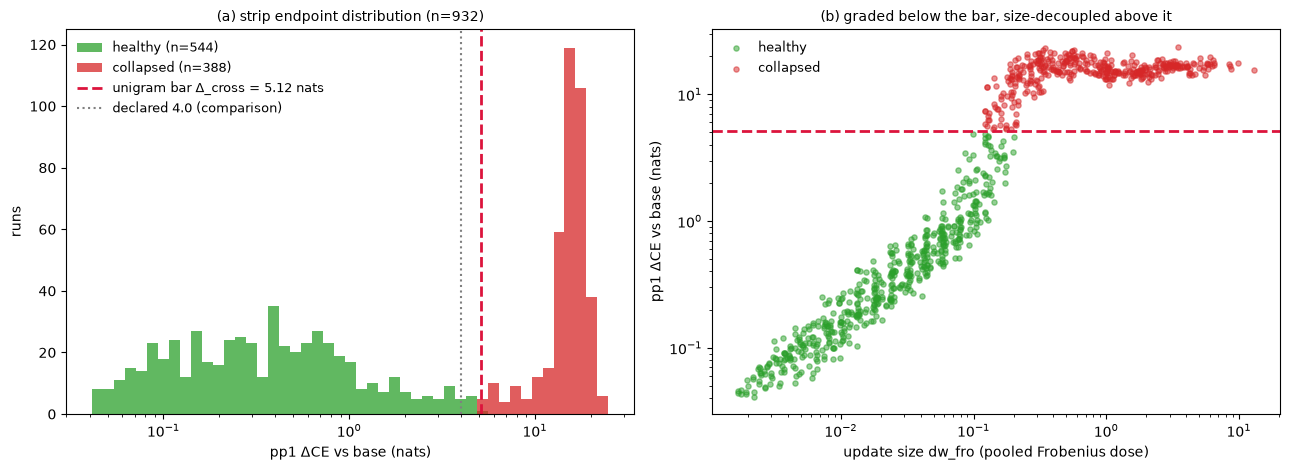

bivariate log-log fits (this cell; the paper quotes the two-part mediation model):
  healthy: R² 0.90, dose slope +0.89   collapsed: R² 0.20, dose slope +0.12


In [3]:
def loglog_fit(d):
    f = sm.OLS(np.log(d.dce), sm.add_constant(np.log(d.dw))).fit(cov_type='cluster', cov_kwds={'groups': d.tag})
    return f.rsquared, float(f.params.iloc[1])
r2_a, sl_a = loglog_fit(sd[~sd.dead]); r2_d, sl_d = loglog_fit(sd[sd.dead])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
bins = np.geomspace(max(sd.dce.min(), 1e-3), sd.dce.max()*1.05, 48)
axes[0].hist(sd[~sd.dead].dce, bins=bins, color='tab:green', alpha=0.75, label=f'healthy (n={int((~sd.dead).sum())})')
axes[0].hist(sd[sd.dead].dce, bins=bins, color='tab:red', alpha=0.75, label=f'collapsed (n={int(sd.dead.sum())})')
axes[0].axvline(DC_DS1, color='crimson', ls='--', lw=2, label=f'unigram bar Δ_cross = {DC_DS1:.2f} nats')
axes[0].axvline(DEAD_KL_CUT, color='gray', ls=':', lw=1.5, label='declared 4.0 (comparison)')
axes[0].set_xscale('log'); axes[0].set_xlabel(KL_LAB)
axes[0].set_ylabel('runs'); axes[0].set_title(f'(a) strip endpoint distribution (n={len(sd)})', fontsize=10)
axes[0].legend(fontsize=9, frameon=False)
axes[1].scatter(sd[~sd.dead].dw, sd[~sd.dead].dce, s=14, c='tab:green', alpha=0.5, label='healthy')
axes[1].scatter(sd[sd.dead].dw, sd[sd.dead].dce, s=14, c='tab:red', alpha=0.5, label='collapsed')
axes[1].axhline(DC_DS1, color='crimson', ls='--', lw=2)
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('update size dw_fro (pooled Frobenius dose)'); axes[1].set_ylabel(KL_LAB)
axes[1].set_title('(b) graded below the bar, size-decoupled above it', fontsize=10)
axes[1].legend(fontsize=9, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig01_event_not_continuum.png', dpi=180, bbox_inches='tight'); plt.show()
print('bivariate log-log fits (this cell; the paper quotes the two-part mediation model):')
print(f'  healthy: R² {r2_a:.2f}, dose slope {sl_a:+.2f}   collapsed: R² {r2_d:.2f}, dose slope {sl_d:+.2f}')

## Figure 2 — §4.2 (size experiments) / §4.6 *λ-rescaling: the full curve families, and the hysteresis*

**Construction.** The λ-rescale campaign (`frozen_a_ablation_{scale,revival,lamstrat,
lamstrat_s2,shellext_s1,shellext_s2,ws1lam}_lam*_pp1.json`): each curve is one finished strip
run whose update is scaled by a ladder of λ values and re-evaluated on pp1 (receiver = ds1
except the ws1lam family). **(a)** every curve's ΔCE vs its dose λ·dw_fro, colored by the
run's own trained fate — the integrity event is monotone in λ on every curve. **(b)** the
kill/revive hysteresis on the calibrated families (lamstrat/shellext): the dose at which
trained-healthy curves cross the cut scaling up vs the dose at which trained-collapsed curves
re-cross scaling down. Paper (anchored, CE-primary, 230 curves): kill 0.158 vs revive 0.125, hysteresis
1.29× [1.23, 1.35] adjusted for α and rank, 1.12× [1.05, 1.20] after further adjusting
for training dose (the KL-era calibrated set gave 0.147/0.115, 1.26×); this cell
recomputes at the anchored cut. Labels and
crossings use each curve's own receiver's translated bar (ds1 Δ_cross 5.123 for all
families except ws1lam, whose receiver is ws1, Δ_cross 5.055); the drawn line is the ds1
value — the 0.07-nat difference is within line width at this scale.

adapter_norms cache: 35495 rows of 44604 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


λ curves: 230 from 12 lambda_families_ce chunks (ΔCE readout, unified 15-λ grid) | with dose: 230 | monotone integrity event: 230/230


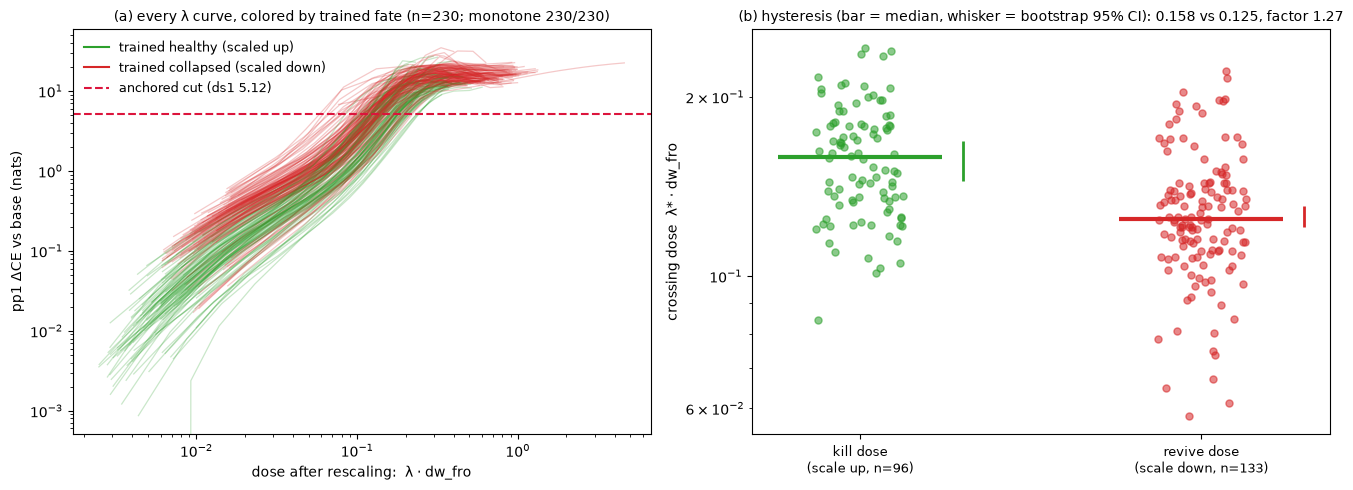

kill median 0.1583 | revive median 0.1246 | raw factor 1.27 (paper, anchored CE-primary: 0.158 / 0.125; 1.29x [1.23,1.35] adjusted, 1.12x [1.05,1.20] after training-dose adjustment)


In [4]:
nrm = load_adapter_norm_runs(OUT)
nrm = nrm[nrm.student_tag.str.startswith('ep20_') & (nrm.teacher == 'ep2_lr5e-4_r32a64_tseed1')]
dwkey = nrm.groupby(['student_base', 'student_tag', 'ftseed']).dw_fro.first()
def run_dir(b, t, s):
    return OUT/'students'/'dog'/b/'teacher-pythia-160m'/'ep2_lr5e-4_r32a64_tseed1'/'ex10-20_prefix_n100k'/t/f'ftseed{s}'
cef2 = sorted(A.glob('lambda_families_ce_*.jsonl'))
USED_CE2 = bool(cef2)
rows = []
if USED_CE2:
    fam_df = pd.concat([read_jsonl(f) for f in cef2], ignore_index=True)
    fam_df['bkey'] = fam_df.base.str.split('/').str[-1]
    for run, g in fam_df.groupby('run'):
        g = g.sort_values('lam'); b = g.bkey.iloc[0]; cut = DCX[b]
        tag = Path(run).parent.name; seed = int(Path(run).name.replace('ftseed', ''))
        lams = list(g.lam.values); kls = g.delta_ce.values.astype(float)
        pp0 = load_probe(Path(run)) or {}
        kl_run = pp0.get('delta_ce', pp0.get('kl_base_student'))
        fate = np.where(np.isfinite(kls) & (kls <= cut), 'A', 'D')
        rows.append(dict(fam='ce', tag=tag, seed=seed, base=b, cut=cut,
                         dw=dwkey.get((b, tag, seed), np.nan), lams=lams, kls=kls,
                         kl_run=kl_run, mono=re.fullmatch(r'A*D*', ''.join(fate)) is not None,
                         lam_cross=interp_crossing(lams, list(kls), cut, rising=True)))
    SRC2 = f'{len(cef2)} lambda_families_ce chunks (ΔCE readout, unified 15-λ grid)'
else:
    FAMS = {'scale': 'frozen_a_ablation_scale_lam*_pp1.json', 'revival': 'frozen_a_ablation_revival_lam*_pp1.json',
            'lamstrat': 'frozen_a_ablation_lamstrat_lam*_pp1.json', 'lamstrat_s2': 'frozen_a_ablation_lamstrat_s2_lam*_pp1.json',
            'shellext_s1': 'frozen_a_ablation_shellext_s1_lam*_pp1.json', 'shellext_s2': 'frozen_a_ablation_shellext_s2_lam*_pp1.json',
            'ws1lam': 'frozen_a_ablation_ws1lam_lam*_pp1.json'}
    curves, cbase = {}, {}
    for fam, pat in FAMS.items():
        for f in _glob.glob(str(A/pat)):
            d = read_json(f); lin = d['lineage']
            for x in d['results']:
                k = (fam, x['student_tag'], x['ftseed'])
                cbase[k] = lin['student_base'] if isinstance(lin, dict) and 'student_base' in lin else 'pythia-160m-data-seed1'
                curves.setdefault(k, {})[d['scale_lambda']] = x['pile_kl_base_ablated']
    for k, cdict in curves.items():
        fam, tag, seed = k; b = cbase[k]; cut = DCX[b]
        lams = sorted(cdict); kls = np.array([cdict[v] for v in lams], float)
        pp0 = load_probe(run_dir(b, tag, seed)) or {}
        kl_run = pp0.get('kl_base_student')
        fate = np.where(np.isfinite(kls) & (kls <= cut), 'A', 'D')
        rows.append(dict(fam=fam, tag=tag, seed=seed, base=b, cut=cut,
                         dw=dwkey.get((b, tag, seed), np.nan), lams=lams, kls=kls,
                         kl_run=kl_run, mono=re.fullmatch(r'A*D*', ''.join(fate)) is not None,
                         lam_cross=interp_crossing(lams, kls, cut, rising=True)))
    SRC2 = 'legacy frozen_a family files (KL readout)'
cv = pd.DataFrame(rows)
cv['trained_dead'] = pd.to_numeric(cv.kl_run, errors='coerce') > cv.cut
have = cv.dropna(subset=['dw'])
YLAB2 = KL_LAB if USED_CE2 else 'pp1 Pile-KL vs base (nats)'
print(f"λ curves: {len(cv)} from {SRC2} | with dose: {len(have)} | "
      f"monotone integrity event: {int(cv.mono.sum())}/{len(cv)}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
for _, r in have.iterrows():
    axes[0].plot(np.array(r.lams)*r.dw, r.kls, '-', color=('tab:red' if r.trained_dead else 'tab:green'),
                 alpha=0.25, lw=0.9)
axes[0].axhline(DC_DS1, color='crimson', ls='--', lw=1.5)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('dose after rescaling:  λ · dw_fro'); axes[0].set_ylabel(YLAB2)
axes[0].set_title(f'(a) every λ curve, colored by trained fate (n={len(have)}; '
                  f'monotone {int(cv.mono.sum())}/{len(cv)})', fontsize=10)
h = [plt.Line2D([], [], color='tab:green', label='trained healthy (scaled up)'),
     plt.Line2D([], [], color='tab:red', label='trained collapsed (scaled down)'),
     plt.Line2D([], [], color='crimson', ls='--', label=f'anchored cut (ds1 {DC_DS1:.2f})')]
axes[0].legend(handles=h, fontsize=9, frameon=False, loc='upper left')
cal = (have if USED_CE2 else have[have.fam.isin(['lamstrat', 'lamstrat_s2', 'shellext_s1', 'shellext_s2'])]).dropna(subset=['lam_cross'])
kill = (cal[~cal.trained_dead].lam_cross * cal[~cal.trained_dead].dw).dropna()
revi = (cal[cal.trained_dead].lam_cross * cal[cal.trained_dead].dw).dropna()
rj = np.random.default_rng(1)
for j, (v, col) in enumerate(((kill, 'tab:green'), (revi, 'tab:red'))):
    axes[1].scatter(j + rj.uniform(-0.13, 0.13, len(v)), v, s=26, alpha=0.55, color=col)
    m, lo, hi = med_ci(v.values)
    axes[1].hlines(m, j-0.24, j+0.24, color=col, lw=3)
    axes[1].vlines(j+0.3, lo, hi, color=col, lw=2)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels([f'kill dose\n(scale up, n={len(kill)})', f'revive dose\n(scale down, n={len(revi)})'], fontsize=9)
axes[1].set_yscale('log'); axes[1].set_ylabel('crossing dose  λ* · dw_fro')
axes[1].set_title(f'(b) hysteresis (bar = median, whisker = bootstrap 95% CI): '
                  f'{np.median(kill):.3f} vs {np.median(revi):.3f}, factor {np.median(kill)/np.median(revi):.2f}', fontsize=10)
plt.tight_layout(); fig.savefig(FIGDIR/'fig02_lambda_families.png', dpi=180, bbox_inches='tight'); plt.show()
print(f'kill median {np.median(kill):.4f} | revive median {np.median(revi):.4f} | raw factor {np.median(kill)/np.median(revi):.2f}'
      ' (paper, anchored CE-primary: 0.158 / 0.125; 1.29x [1.23,1.35] adjusted, 1.12x [1.05,1.20] after training-dose adjustment)')

## Figure 3 — §4.2 (size experiments) / §4.6 *The training-time clamp*

**Construction.** Clamp runs (`{output_root}/clamp_students/fro-c<ratio>/…`) train at
otherwise-lethal strip hyperparameters with the update's Frobenius norm capped at
ratio × the per-rank θ̂; once a run's update reaches the cap it stays there for the rest of
training. A free-running strip run that *ends* at the same size spent most of training below
it and merely arrived there. **(a)** alive fraction vs clamp ceiling. **(b)** P(collapsed)
at matched *final* size (per-rank anchored θ̂ from the strip's dead-edge; shaded band =
0.7–1.0×θ̂): at the same endpoint size, the held-at-size runs die far more often than the
arrived-at-size runs — the training-time dose is path-dependent. Paper: 19/38 vs 6/72.

clamp runs (fro): 124 probed 124 | unclamped comparison runs: 349


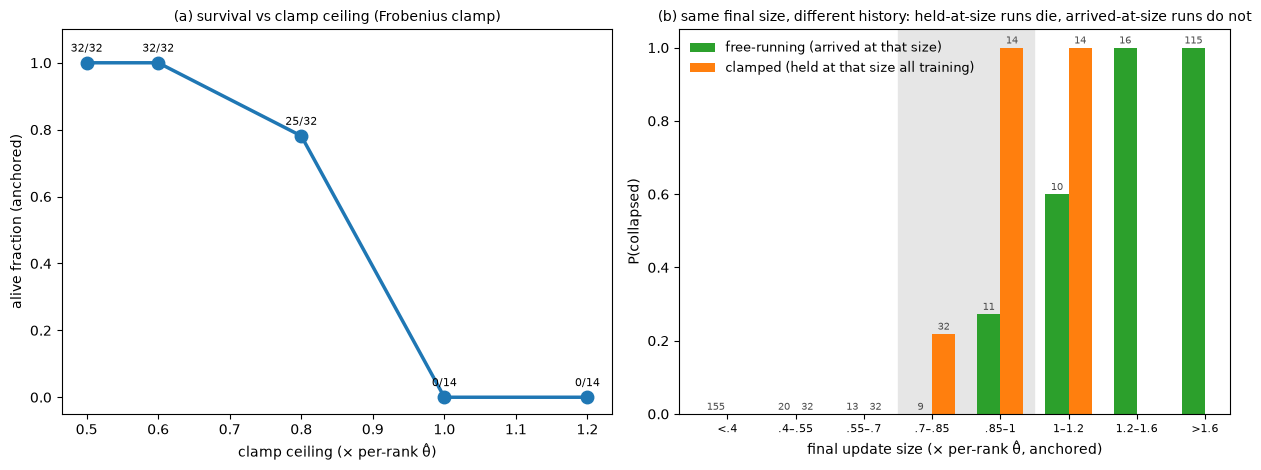

0.7–1.0×θ̂ band: clamped 21/46 dead vs free 0/17 (paper: 19/38 vs 6/72)
ceiling 0.5×θ̂: 32/32 alive | ceiling ≥1.0×θ̂: 0/28 alive (paper: 32/32 and 0/28)


In [5]:
def dead_edge(x, y):
    o = np.argsort(x); x, y = np.asarray(x)[o], np.asarray(y)[o]
    N = len(x); cum = np.r_[0, np.cumsum(y)]
    acc = np.array([((i - cum[i]) + (cum[-1] - cum[i])) / N for i in range(N + 1)])
    i = int(np.argmax(acc)); return float(x[i]) if i < N else np.nan
theta_rank = {rk: dead_edge(g.dw, g.dead.astype(int)) for rk, g in sd.groupby('rank')}
rows = []
for labdir in sorted((OUT/'clamp_students').iterdir()):
    lab = labdir.name
    if lab == 'ckpt-replay' or '-c' not in lab: continue
    norm, c = lab.split('-c'); ratio = float(c.replace('p', '.'))
    for mf in _glob.glob(str(labdir/'*/*/*/*/*/*/*/train_manifest.json')):
        rd = Path(mf).parent
        pr = load_probe(rd) or {}
        try:
            log = [json.loads(l) for l in (rd/'clamp_log.jsonl').read_text().splitlines()]
        except FileNotFoundError:
            continue
        tag = rd.parent.name; mrank = int(re.search(r'_r(\d+)a', tag).group(1))
        rows.append(dict(norm=norm, ratio=ratio, tag=tag, rank=mrank,
                         dce=pr.get('delta_ce', pr.get('kl_base_student')), dose_final=log[-1]['dose']))
clamp = pd.DataFrame(rows)
clamp['dce'] = pd.to_numeric(clamp.dce, errors='coerce')
clamp['dead'] = (~np.isfinite(clamp.dce)) | (clamp.dce > DC_DS1)
cf = clamp[clamp.norm == 'fro'].copy()
cf['x'] = cf.dose_final / cf['rank'].map(theta_rank)
su = sd[sd['rank'].isin(sorted(cf['rank'].unique()))].copy()
su['x'] = su.dw / su['rank'].map(theta_rank)
print(f"clamp runs (fro): {len(cf)} probed {int(cf.dce.notna().sum())} | unclamped comparison runs: {len(su)}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ag = cf.groupby('ratio').agg(alive=('dead', lambda s: 1 - s.mean()), n=('dead', 'size')).reset_index()
axes[0].plot(ag.ratio, ag.alive, 'o-', color='tab:blue', lw=2.5, ms=9)
for _, r in ag.iterrows():
    axes[0].annotate(f"{int(round(r.alive*r.n))}/{int(r.n)}", (r.ratio, r.alive), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=8)
axes[0].set_xlabel('clamp ceiling (× per-rank θ̂)'); axes[0].set_ylabel('alive fraction (anchored)')
axes[0].set_ylim(-0.05, 1.1); axes[0].set_title('(a) survival vs clamp ceiling (Frobenius clamp)', fontsize=10)
bins = [0, 0.4, 0.55, 0.7, 0.85, 1.0, 1.2, 1.6, 100]
bl = ['<.4', '.4–.55', '.55–.7', '.7–.85', '.85–1', '1–1.2', '1.2–1.6', '>1.6']
for d, lab, col, off in ((su, 'free-running (arrived at that size)', 'tab:green', -0.17),
                         (cf, 'clamped (held at that size all training)', 'tab:orange', 0.17)):
    g = d.groupby(pd.cut(d.x, bins), observed=False).dead.agg(['mean', 'size'])
    xs = np.arange(len(g))
    axes[1].bar(xs + off, g['mean'], 0.34, color=col, label=lab)
    for xi, (m, n_) in zip(xs, g.values):
        if n_ > 0: axes[1].annotate(int(n_), (xi + off, m), textcoords='offset points', xytext=(0, 3),
                                    ha='center', fontsize=7, color='0.3')
axes[1].axvspan(2.5, 4.5, color='0.9', zorder=0)
axes[1].set_xticks(np.arange(len(bl))); axes[1].set_xticklabels(bl, fontsize=8)
axes[1].set_xlabel('final update size (× per-rank θ̂, anchored)'); axes[1].set_ylabel('P(collapsed)')
axes[1].set_title('(b) same final size, different history: held-at-size runs die, arrived-at-size runs do not', fontsize=10)
axes[1].legend(fontsize=9, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig03_clamp.png', dpi=180, bbox_inches='tight'); plt.show()
b1 = cf[(cf.x >= 0.7) & (cf.x < 1.0)]; b2 = su[(su.x >= 0.7) & (su.x < 1.0)]
print(f'0.7–1.0×θ̂ band: clamped {int(b1.dead.sum())}/{len(b1)} dead vs free {int(b2.dead.sum())}/{len(b2)} (paper: 19/38 vs 6/72)')
lo = cf[np.isclose(cf.ratio, 0.5)]; hi = cf[cf.ratio >= 1.0]
print(f'ceiling 0.5×θ̂: {int((~lo.dead).sum())}/{len(lo)} alive | ceiling ≥1.0×θ̂: {int((~hi.dead).sum())}/{len(hi)} alive '
      '(paper: 32/32 and 0/28)')

## Table 1 + Figure 11 — §4.2 (direction experiments) *The direction surgery, Randomized variant: the color-graded table, and census-scale healing*

**Construction.** **Table 1** (the 158-run ce-wave campaign, `position_surgery_ce_*.jsonl`,
four arms; singular-vector pairs replaced by fresh random orthonormal sets — two draws
averaged — or moved onto the base's own top singular pairs (W₀-aligned), per-module spectrum
byte-identical): rows = arm; column blocks = collapse-depth band (by the run's
trained-directions damage); within each block, the median pp1 ΔCE under trained /
W₀-aligned / randomized singular vectors over the anchored-dead runs. Green→red = low→high;
**bold = median below the run's own receiver's translated bar (healed to alive)**; the count
table gives n per arm × band. **Figure 11** (the 08-28 census,
`position_surgery_cen_{arm}_s*.jsonl`: Randomized + W₀-aligned on the outcome-blind frozen
lists of all six arms of the dog | orig lineage — 2,618 listed runs; runs with a stored
probe and both variants on disk enter, n printed): trained damage (stored probe, the KL
twin) vs the Randomized variant's ΔCE, one panel per arm, cut lines on both axes — the
below-diagonal mass at matched size IS direction dependence, and the annotation gives the
census revival fraction among anchored-dead runs — depth-dominated, since the census
includes runs far past the boundary where the Randomized variant is itself dead (the
validity structure Figure 12b resolves); near the boundary revival is ~100% (Table 1). The census audit (a fixed 1-in-5 sublist
re-running the trained reconstruction and a second random draw) reproduces the stored
probes; its median |orig − stored| is printed. CSVs in `paper_figures/` for typesetting. Each run's baseline ΔCE is the paired `original_delta_ce` when the artifact carries it and otherwise that run's stored pp1 probe ΔCE; the per-arm source counts are printed under each figure.

In [ ]:
from subliminal_learning.weightspace.deltas import surgery_original_delta_ce

ce_main = [f for f in sorted(A.glob('position_surgery_ce_*.jsonl')) if not f.name.endswith('_prog.jsonl')]
USED_CES = bool(ce_main)
df = (pd.concat([read_jsonl(f) for f in ce_main], ignore_index=True) if USED_CES
      else read_jsonl(A/'position_surgery_v2.jsonl'))
df['val'] = df['delta_ce'] if 'delta_ce' in df.columns else df['pile_kl']
YLABS = KL_LAB if USED_CES else 'pp1 Pile-KL vs base (nats)'
print('surgery source:', f'{len(ce_main)} position_surgery_ce arms (ΔCE)' if USED_CES else 'position_surgery_v2 (KL)')
def surg_arm(r):
    if '/teachers/' in r: return 'teacher(orig)'
    if '/controls/' in r: return 'traitfree(ds1)'
    if '/students/dog/pythia-160m/' in r: return 'samemodel(orig)'
    return 'strip(ds1)'
df['arm'] = df.run.map(surg_arm)
pv = df.pivot_table(index=['arm', 'run'], columns='variant', values='val').reset_index()
pv['randm'] = pv[['rand0', 'rand1']].mean(axis=1)
pv['dc'] = np.where(pv.arm.str.contains('orig'), DC_ORIG, DC_DS1)
pv['dead'] = pv['orig'] > pv['dc']
pp = df.pivot_table(index=['arm', 'run'], columns='variant', values='p_target').reset_index()
pp['randm'] = pp[['rand0', 'rand1']].mean(axis=1)
mm = pv.merge(pp, on=['arm', 'run'], suffixes=('_kl', '_p'))
ARMS = ['strip(ds1)', 'samemodel(orig)', 'teacher(orig)', 'traitfree(ds1)']
dead = pv[pv.dead].copy()
dead['band'] = pd.cut(dead.orig, [0, 9, 12, np.inf], labels=['cut–9 nats', '9–12 nats', '>12 nats'])
POSL = {'orig': 'trained', 'align': 'W0-aligned', 'randm': 'randomized'}
long = dead.melt(id_vars=['arm', 'band'], value_vars=['orig', 'align', 'randm'],
                 var_name='source', value_name='kl')
long['source'] = long.source.map(POSL)
tab = long.pivot_table(index='arm', columns=['band', 'source'], values='kl', aggfunc='median', observed=True)
cols = pd.MultiIndex.from_product([['cut–9 nats', '9–12 nats', '>12 nats'],
                                   ['trained', 'W0-aligned', 'randomized']], names=['band', 'source'])
tab = tab.reindex(index=ARMS, columns=cols)
cnt = dead.groupby(['arm', 'band'], observed=True).size().unstack().reindex(index=ARMS)
DCROW = {'strip(ds1)': DC_DS1, 'samemodel(orig)': DC_ORIG, 'teacher(orig)': DC_ORIG, 'traitfree(ds1)': DC_DS1}
sty = (tab.style.background_gradient(cmap='RdYlGn_r', axis=None, vmin=0.0, vmax=15.0)
       .format('{:.1f}', na_rep='—')
       .apply(lambda row: ['font-weight: bold' if pd.notna(v) and v < DCROW[row.name] else '' for v in row], axis=1)
       .set_caption('Table 1 — anchored-dead runs (158-run ce-wave campaign): median pp1 ΔCE vs base (nats), '
                    'arm × singular-vector source, one column block per collapse-depth band. '
                    'Bold = healed below its own receiver bar.'))
display(sty)
print('n (anchored-dead runs) per arm × band:')
display(cnt)
tab.to_csv(FIGDIR/'table1_surgery_medians.csv'); cnt.to_csv(FIGDIR/'table1_surgery_counts.csv')
print('anchored-dead median ΔCE per arm (paper §4.2: 9.9→1.7 / 11.7→3.0 / 6.9→0.00 / 9.0→6.9):')
print(pv[pv.dead].groupby('arm')[['orig', 'align', 'randm']].median().round(2).loc[ARMS].to_string())

# ---- Figure 11: the 08-28 census (Randomized + W0-aligned, all six arms) ----
CEN_ARMS = {'strip': ('strip (ds1)', 'pythia-160m-data-seed1'),
            'samemodel': ('orig same-model', 'pythia-160m'),
            'traitfree': ('trait-free (ds1)', 'pythia-160m-data-seed1'),
            'teachers': ('teachers (orig)', 'pythia-160m'),
            'm410same': ('410M same-model', 'pythia-410m'),
            'm410cross': ('410M cross-seed', 'pythia-410m-seed1')}
CEN = {}
for a_, (lab_, b_) in CEN_ARMS.items():
    d_ = pd.concat([read_jsonl(f) for f in sorted(A.glob(f'position_surgery_cen_{a_}_s*.jsonl'))],
                   ignore_index=True)
    c_ = d_.pivot_table(index='run', columns='variant', values='delta_ce', aggfunc='first')
    base_, src_ = surgery_original_delta_ce(d_.to_dict('records'))
    c_['stored'] = pd.Series(base_).reindex(c_.index)
    c_['baseline_src'] = pd.Series(src_).reindex(c_.index)
    c_ = c_[np.isfinite(c_['stored'])]
    c_['cut'] = DCX[b_]
    CEN[a_] = c_
    n_ = c_.baseline_src.value_counts()
    print(f"{a_}: baseline source paired {int(n_.get('paired', 0))} / "
          f"stored_probe {int(n_.get('stored_probe', 0))} / "
          f"missing {int((pd.Series(src_) == 'missing').sum())}")
aud = pd.concat([read_jsonl(f) for f in sorted(A.glob('position_surgery_cen_*_audit.jsonl'))], ignore_index=True)
AUD_BASE, AUD_SRC = surgery_original_delta_ce(aud.to_dict('records'))
_as = pd.Series(AUD_SRC).value_counts()
print(f"audit: baseline source paired {int(_as.get('paired', 0))} / "
      f"stored_probe {int(_as.get('stored_probe', 0))} / missing {int(_as.get('missing', 0))}")
ao = aud[aud.variant == 'orig']
_ad = (ao.delta_ce - ao.run.map(AUD_BASE)).abs()
print(f"census on disk: {sum(len(c) for c in CEN.values())} runs with both variants (2,618-run frozen lists); "
      f"audit |orig − baseline ΔCE|: median {float(_ad[np.isfinite(_ad)].median()):.4f} nats over "
      f"{int(np.isfinite(_ad).sum())} re-runs with a finite baseline")
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.2))
for ax, (a_, (lab_, b_)) in zip(axes.ravel(), CEN_ARMS.items()):
    c_ = CEN[a_]; cut_ = c_.cut.iloc[0]
    dead_ = c_.stored > cut_
    ax.plot(c_.stored[~dead_], c_.rand0[~dead_], 'o', color='tab:green', ms=4, alpha=0.45, label='healthy (trained)')
    ax.plot(c_.stored[dead_], c_.rand0[dead_], 'o', color='tab:red', ms=4, alpha=0.45, label='collapsed (trained)')
    lim = float(np.nanmax([c_.stored.max(), c_.rand0.max()])) * 1.05
    ax.plot([0, lim], [0, lim], '-', color='0.6', lw=1)
    ax.axhline(cut_, color='crimson', ls='--', lw=1.2); ax.axvline(cut_, color='crimson', ls='--', lw=1.2)
    rev = float((c_.rand0[dead_] < cut_).mean()) if dead_.any() else np.nan
    ax.set_title(f'{lab_} (n={len(c_)}; dead {int(dead_.sum())}, randomized revives {rev:.0%})', fontsize=10)
    ax.set_xlabel('trained damage (baseline ΔCE, nats)')
axes[0, 0].set_ylabel('Randomized-variant ΔCE (nats)'); axes[1, 0].set_ylabel('Randomized-variant ΔCE (nats)')
axes[0, 0].legend(fontsize=8, frameon=False, loc='upper left')
fig.suptitle('Figure 11 — census-scale direction dependence: same strengths, randomized singular vectors',
             fontsize=11, y=1.0)
plt.tight_layout(); fig.savefig(FIGDIR/'fig11_census_healing.png', dpi=180, bbox_inches='tight'); plt.show()
cenmed = pd.DataFrame({lab_: {'trained (baseline)': CEN[a_].loc[CEN[a_].stored > CEN[a_].cut.iloc[0], 'stored'].median(),
                              'W0-aligned': CEN[a_].loc[CEN[a_].stored > CEN[a_].cut.iloc[0], 'align'].median(),
                              'randomized': CEN[a_].loc[CEN[a_].stored > CEN[a_].cut.iloc[0], 'rand0'].median()}
                       for a_, (lab_, b_) in CEN_ARMS.items()}).T.round(2)
print('census anchored-dead medians (nats), trained / W0-aligned / randomized per arm\n'
      '(the 158-campaign reading "aligned intermediate" holds on four of six arms at census depth;\n'
      ' same-model and trait-free dead medians have aligned ≈ randomized):')
print(cenmed.to_string())
cenmed.to_csv(FIGDIR/'fig11_census_medians.csv')


## Table 1b — §4.2 (direction experiments) *Selector endpoints: the content sits in the strongest few directions*

**Construction.** The selector campaign (08-29, `position_surgery_sub_{arm}_s*.jsonl`, run
on the 546-run subset where the direction effect is defined — the Randomized denominator
below the receiver's anchored cut): per run, replace only the selected singular-vector
pairs at full rotation (t = 1). Selectors: **Top-k** = the k strongest pairs randomized;
**Rest-k** = everything *but* the k strongest randomized (top-k kept trained — the ledger's
"bottom randomized"). Row unit: one arm; cell = median pp1 ΔCE over that arm's
anchored-dead runs (dead by the stored probe) under that selector; the companion table
gives the revival fraction (ΔCE brought below the receiver's bar). Paper quotes (§4.2):
Top-4 revives 85–100% per student arm (12 → 2.3 nats), Rest-4 16–47% (stays 8–10 nats);
teachers Top-1 97% (32.7 → 0.4), Rest-4 0%. The supercritical/subcritical selectors from
the same campaign are rendered with §5.2 (Fig 14). Skips (a selector with nothing to
replace) are recorded in the artifacts (n_super / n_dirs / n_reaimed) and simply absent
here.


In [ ]:
SEL_ARMS = CEN_ARMS  # same six arms / receiver bases as the census
SELDF, SELT = {}, {}
for a_, (lab_, b_) in SEL_ARMS.items():
    s_ = pd.concat([read_jsonl(f) for f in sorted(A.glob(f'position_surgery_sub_{a_}_s*.jsonl'))], ignore_index=True)
    t_ = pd.concat([read_jsonl(f) for f in sorted(A.glob(f'position_surgery_subt_{a_}_s*.jsonl'))], ignore_index=True)
    for d_ in (s_, t_):
        d_['sel'] = d_.variant.str.split('@').str[0]
        d_['t'] = d_.variant.str.split('@').str[1].astype(float).fillna(1.0)
        b_, sb_ = surgery_original_delta_ce(d_.to_dict('records'))
        d_['stored'] = d_.run.map(b_)
        d_['baseline_src'] = d_.run.map(sb_)
    n_ = pd.concat([s_.baseline_src, t_.baseline_src]).value_counts()
    print(f"{a_}: baseline source paired {int(n_.get('paired', 0))} / "
          f"stored_probe {int(n_.get('stored_probe', 0))} / missing {int(n_.get('missing', 0))} (rows)")
    s_['cut'] = DCX[b_]; t_['cut'] = DCX[b_]
    SELDF[a_], SELT[a_] = s_, t_
SELS = ['top1', 'top2', 'top4', 'rest1', 'rest2', 'rest4']
rows_, revs_, ns_ = {}, {}, {}
for a_, (lab_, b_) in SEL_ARMS.items():
    s_ = SELDF[a_]; cut_ = DCX[b_]
    dd = s_[(s_.stored > cut_) & s_.sel.isin(SELS)]
    rows_[lab_] = dd.groupby('sel')['delta_ce'].median()
    revs_[lab_] = dd.groupby('sel')['delta_ce'].apply(lambda v: float((v < cut_).mean()))
    ns_[lab_] = dd.groupby('sel')['run'].nunique()
t1b = pd.DataFrame(rows_).T.reindex(columns=SELS)
t1b_rev = pd.DataFrame(revs_).T.reindex(columns=SELS)
t1b_n = pd.DataFrame(ns_).T.reindex(columns=SELS)
sty = (t1b.style.background_gradient(cmap='RdYlGn_r', axis=None, vmin=0.0, vmax=15.0)
       .format('{:.1f}', na_rep='—')
       .set_caption('Table 1b — anchored-dead runs of the 546-run selector subset: median pp1 ΔCE vs base (nats) '
                    'after randomizing ONLY the selected singular-vector pairs (Top-k = k strongest randomized; '
                    'Rest-k = all but the k strongest randomized, top-k kept trained). Row = arm.'))
display(sty)
sty2 = (t1b_rev.style.background_gradient(cmap='RdYlGn', axis=None, vmin=0.0, vmax=1.0)
        .format('{:.0%}', na_rep='—')
        .set_caption('Table 1b companion — revival fraction: share of those anchored-dead runs brought below their '
                     'receiver bar by the selector alone (n per cell in the counts CSV).'))
display(sty2)
t1b.to_csv(FIGDIR/'table1b_selector_medians.csv'); t1b_rev.to_csv(FIGDIR/'table1b_selector_revival.csv')
t1b_n.to_csv(FIGDIR/'table1b_selector_counts.csv')
print('paper spot-checks — Top-4 revival per student arm 85–100%, Rest-4 16–47%; teachers Top-1 97%, Rest-4 0%:')
print(t1b_rev[['top4', 'rest4', 'top1']].round(2).to_string())
print('denominator-valid subset runs per arm (paper: 141/83/61/147/67/47):',
      {lab: int(SELDF[a].run.nunique()) for a, (lab, b) in SEL_ARMS.items()})


## Figure 4 — §4.2 (direction experiments) *The rotation amount t: graded, no threshold in direction space*

**Construction.** **(a)** the all-pairs progression (`position_surgery_ce_prog.jsonl`, 12
strip runs): every singular-vector pair rotated a fraction t toward random — t = 1 is the
Randomized variant. **(b, c)** the selector rotation grid (08-29,
`position_surgery_subt_{arm}_s*.jsonl`, with each selector's t = 1 endpoint from the
selector files): median ΔCE over anchored-dead runs along t ∈ {0.25, 0.5, 0.75, 1} per
selector — strip and teachers panels; each line aggregates only runs with a complete
ladder for that selector, so the population is fixed along t (a selector whose selection
is empty on an arm — supercritical on teachers, where only 2% of runs have any
supercritical pair — has no populated ladder and is omitted). Damage falls smoothly along the rotation: pooled per selector, 90–99% of dead runs are
monotone non-increasing at a 5% relative tolerance (the convention that reproduces the
ledger's "87–100%" reading); at a strict 0.05-nat absolute tolerance the per-arm ×
selector range widens to 0.67–1.00 — the printed table gives both, per-arm fractions in
the CSV. Paper quotes: strip Top-4 11.6 → 5.3 → 2.7 → 2.3; teachers Top-4
28.7 → 8.2 → 0.2 → 0.1.


In [ ]:
pr = read_jsonl(A/'position_surgery_ce_prog.jsonl')
from subliminal_learning.weightspace.deltas import surgery_record_is_current
if not all(surgery_record_is_current(r, require_keyed_targets=True) for r in pr.to_dict("records")):
    raise ValueError("Legacy randt records: rerun position_surgery with the original t_ladder before plotting.")
pr['val'] = pr['delta_ce']
def t_of(v): return 0.0 if v == 'orig' else (1.0 if v == 'rand0' else (float(v[5:]) if v.startswith('randt') else np.nan))
pr['t'] = pr.variant.map(t_of); pr = pr.dropna(subset=['t'])
prp = pr.pivot_table(index='run', columns='t', values='val'); pdead = prp[0.0] > DC_DS1
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.8))
ax = axes[0]
for _, row in prp.iterrows():
    ax.plot(prp.columns, row.values, '-', color=('tab:red' if row[0.0] > DC_DS1 else 'tab:green'), alpha=0.3, lw=1)
ax.plot(prp.columns, prp[pdead].median(), 'o-', color='tab:red', lw=2.5, ms=8, label='collapsed runs (median)')
ax.plot(prp.columns, prp[~pdead].median(), 's-', color='tab:green', lw=2.5, ms=8, label='healthy runs (median)')
ax.axhline(DC_DS1, color='crimson', ls='--', lw=1.5)
ax.set_xlabel('rotation amount t (0 = trained, 1 = random)'); ax.set_ylabel(KL_LAB)
ax.set_title('(a) all pairs (Randomized), 12 strip runs', fontsize=10)
ax.legend(fontsize=8, frameon=False)
SEL_ORDER = ['top1', 'top2', 'top4', 'rest1', 'rest2', 'rest4', 'sub', 'super']
SELC = dict(zip(SEL_ORDER, plt.cm.tab10.colors))
for ax, a_, pl_ in ((axes[1], 'strip', '(b) selectors, strip (ds1)'), (axes[2], 'teachers', '(c) selectors, teachers (orig)')):
    cut_ = SELT[a_].cut.iloc[0]
    both = pd.concat([SELT[a_], SELDF[a_]], ignore_index=True)
    dd = both[both.stored > cut_]
    for sel in SEL_ORDER:
        pt_ = dd[dd.sel == sel].pivot_table(index='run', columns='t', values='delta_ce').dropna()
        if len(pt_) < 5: continue  # empty-selection selectors (supercritical on teachers) have no populated ladder
        med = pt_.median(axis=0)
        ax.plot(med.index, med.values, 'o-', color=SELC[sel], lw=2, ms=6, label=sel)
    ax.axhline(cut_, color='crimson', ls='--', lw=1.5)
    ax.set_xlabel('rotation amount t'); ax.set_title(f'{pl_}, anchored-dead runs', fontsize=10)
h4, l4 = axes[1].get_legend_handles_labels()
axes[2].legend(h4, l4, fontsize=8, frameon=False, loc='center left', bbox_to_anchor=(1.01, 0.5),
               title='selector', title_fontsize=9)  # legend from the strip panel — the superset of drawn selectors; per-panel n in the CSV
plt.tight_layout(); fig.savefig(FIGDIR/'fig04_rotation_progression.png', dpi=180, bbox_inches='tight'); plt.show()
allb4 = []
for a_, (lab_, b_) in SEL_ARMS.items():
    b4 = pd.concat([SELT[a_], SELDF[a_]], ignore_index=True)
    allb4.append(b4[b4.stored > DCX[b_]].assign(armlab=lab_))
allb4 = pd.concat(allb4, ignore_index=True)
def _mono_fracs(pt_):
    vals = pt_.values
    return (float(np.mean([np.all(np.diff(r) <= 0.05 * np.maximum(r[:-1], 1e-6)) for r in vals])),
            float(np.mean([np.all(np.diff(r) <= 0.05) for r in vals])))
mono_rows = []
for sel in SEL_ORDER:
    pt_ = allb4[allb4.sel == sel].pivot_table(index=['armlab', 'run'], columns='t', values='delta_ce').dropna()
    if len(pt_) < 5 or pt_.shape[1] < 3: continue
    rel_, abs_ = _mono_fracs(pt_)
    mono_rows.append({'selector': sel, 'n (pooled)': len(pt_),
                      'monotone, 5% rel tol': rel_, 'monotone, 0.05-nat abs tol': abs_})
mono = pd.DataFrame(mono_rows).set_index('selector')
print('fraction of anchored-dead runs monotone non-increasing along t, POOLED across the six arms '
      '(row unit = one selector; a run enters with a complete t ladder; two tolerance conventions '
      '— the 5%-relative column is the convention that reproduces the ledger reading):')
print(mono.round(2).to_string())
per_arm4 = []
for (al_, sel), g4 in allb4.groupby(['armlab', 'sel']):
    pt_ = g4.pivot_table(index='run', columns='t', values='delta_ce').dropna()
    if len(pt_) < 5 or pt_.shape[1] < 3: continue
    rel_, abs_ = _mono_fracs(pt_)
    per_arm4.append({'arm': al_, 'selector': sel, 'n': len(pt_), 'rel5pct': rel_, 'abs0.05': abs_})
pa4 = pd.DataFrame(per_arm4)
pa4.to_csv(FIGDIR/'fig04_monotone_fractions.csv', index=False)
print(f"per-arm × selector fractions → fig04_monotone_fractions.csv "
      f"(abs-tol range {pa4['abs0.05'].min():.2f}–{pa4['abs0.05'].max():.2f}, "
      f"rel-tol range {pa4['rel5pct'].min():.2f}–{pa4['rel5pct'].max():.2f})")


## Figure 5 — §4.2 *Injection ladders: matched-Frobenius vs matched-σ, and the donor-direction ladders*

**Construction.** Synthetic injections into the ds1 base; E is in units of the per-module
RMT threshold θ̄. **(a)** matched **total Frobenius** energy (`diffuse_ladder`): damage is
flat in the direction count k; matched **per-direction σ** (`specmatch_ladder`, total energy
grows as √k): damage rises with k exactly as the total energy does. **(b, c)** the
donor-direction ladder at k = 16 and k = 32 over the full energy grading E = 0.5–4:
injections along the top-k singular directions of a real donor adapter — one donor was a
collapsed run, one a healthy run; "donor" names where the directions came from, the
recipient is always the clean ds1 base — against random directions at the same k and E.
Learned directions are far more damaging at every energy, and the healthy donor's are as
potent as the collapsed donor's. The KL readout saturates and can go non-monotone at E = 4
(ledger caveat).

In [ ]:
def load_ladder(name):
    fce = A/f'{name}_ce.json'
    d_ = read_json(fce if fce.exists() else A/f'{name}.json')
    fr = pd.DataFrame(d_['results'])
    fr['y'] = fr['delta_ce'] if 'delta_ce' in fr.columns else fr['kl']
    return fr, fce.exists()
dif, lce1 = load_ladder('diffuse_ladder_surgery_ds1')
spc, lce2 = load_ladder('specmatch_ladder_surgery_ds1')
trd, lce3 = load_ladder('trained_direction_ladder_ds1')
YLABL = KL_LAB if (lce1 and lce2 and lce3) else 'pp1 Pile-KL vs base (nats)'
print('ladder sources CE?', dict(diffuse=lce1, specmatch=lce2, trained=lce3))
dif['intr'] = dif.intruder_mods.str.split('/').str[0].astype(int)
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), sharey=False)
for al, lab, col in (('g', 'random directions', 'tab:blue'), ('a', 'W0-aligned', 'tab:orange')):
    g = dif[(dif['align'] == al) & (dif.E == 1.0)].sort_values('k')
    axes[0].plot(g.k, g.y, 'o-', color=col, lw=2.2, ms=8, label=f'{lab}, matched TOTAL energy (E=1)')
for al, lab, col in (('g', 'random directions', 'tab:blue'), ('a', 'W0-aligned', 'tab:orange')):
    g = spc[(spc['align'] == al) & (spc.E == 0.5)].sort_values('k')
    axes[0].plot(g.k, g.y, 's--', color=col, lw=1.8, ms=7, alpha=0.7, label=f'{lab}, matched PER-DIRECTION σ (E=0.5)')
axes[0].axhline(DC_DS1, color='crimson', ls=':', lw=1.2)
axes[0].set_xscale('log', base=2); axes[0].set_xlabel('number of injected directions k')
axes[0].set_ylabel(YLABL)
axes[0].set_title('(a) flat in k at matched energy;\nrises with k only as energy grows', fontsize=10)
axes[0].legend(fontsize=8, frameon=False)
EE = [0.5, 1.0, 2.0, 4.0]
for ax, k_ in ((axes[1], 16), (axes[2], 32)):
    for lab, cond, col in (('random directions', None, '0.5'),
                           ('collapsed-donor directions', 'tdead', 'tab:red'),
                           ('healthy-donor directions', 'talive', 'tab:green')):
        if cond is None:
            y = [float(dif[(dif['align'] == 'g') & (dif.k == k_) & (dif.E == e)].y.iloc[0]) for e in EE]
        else:
            y = [float(trd[(trd.cond == cond) & (trd.k == k_) & (trd.E == e)].y.iloc[0]) for e in EE]
        ax.plot(EE, y, 'o-', color=col, lw=2.2, ms=8, label=lab)
    ax.axhline(DC_DS1, color='crimson', ls=':', lw=1.2)
    ax.set_xscale('log', base=2); ax.set_xlabel('injection energy E (× per-module θ̄)')
    ax.set_title(f'({"b" if k_ == 16 else "c"}) donor-direction ladder, k = {k_}', fontsize=10)
axes[1].set_ylabel(YLABL)
axes[1].legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig05_injection_ladders.png', dpi=180, bbox_inches='tight'); plt.show()
print('paper anchors: flat-in-k 12.1→10.6 (E=1 generic, k 1→32); trained vs random k=16,E=1: 29.7/41.4 vs 10.8; '
      'k=32,E=2: 52.0 vs 13.7')

## Table 2 — §4.2 / §5.2 *Damage vs intruder counts on the full k × E grid*

**How to read it.** The near-constancy along each ROW of Table 2a is the finding: at matched
total energy, damage does not care how many directions carry it — one strong direction
(k = 1) and 32 weak ones (k = 32) do the same damage. Damage moves only down the COLUMNS
(with total energy E). What *does* change along the rows is Table 2b: the intruder count
collapses as the energy spreads (random source), and is **zero at every cell** for
the W₀-aligned source — which still kills from E ≥ 2 (bold in 2a). Damage and intruders
dissociate on the full grid. Data: `diffuse_ladder_surgery_ds1.json` (all-48-module intruder
pass); the trained-direction ladder's intruder spot-check used 8 modules (different
denominator) and is quoted in §5.2 instead.

In [ ]:
difl = dif.copy()
difl['position'] = difl['align'].map({'g': 'random directions', 'a': 'W0-aligned'})
kcols = pd.MultiIndex.from_product([['random directions', 'W0-aligned'], [1, 2, 4, 8, 16, 32]],
                                   names=['position', 'k'])
dmg = difl.pivot_table(index='E', columns=['position', 'k'], values='y').reindex(columns=kcols)
intr = difl.pivot_table(index='E', columns=['position', 'k'], values='intr').reindex(columns=kcols)
sty_d = (dmg.style.background_gradient(cmap='RdYlGn_r', axis=None, vmin=0.0, vmax=18.0)
         .format('{:.1f}')
         .map(lambda v: 'font-weight: bold' if pd.notna(v) and v > DC_DS1 else '')
         .set_caption('Table 2a — damage: pp1 Pile-KL vs base (nats), E × (position, k). '
                      'Bold = past the unigram bar. Rows ≈ constant: direction count does not gate damage.'))
sty_i = (intr.style.background_gradient(cmap='Purples', axis=None, vmin=0.0, vmax=48.0)
         .format('{:.0f}')
         .set_caption('Table 2b — intruder modules (of 48) at the same cells: high and k-dependent for random '
                      'position, zero everywhere for W0-aligned.'))
display(sty_d)
display(sty_i)
dmg.to_csv(FIGDIR/'table2a_ladder_damage.csv'); intr.to_csv(FIGDIR/'table2b_ladder_intruders.csv')
al2 = difl[(difl.position == 'W0-aligned') & (difl.E >= 2.0)]
print(f'aligned E≥2 cells: intruders max {int(al2.intr.max())}, damage {al2.y.min():.1f}–{al2.y.max():.1f} nats '
      '— kills with zero intruders')

## Figure 12 — §4.3 *The direction effect: ~600× between arms, ~2–3× within; depth-independence on the defined region*

**Construction.** **(a)** per-run direction effect log(ΔCE_trained / ΔCE_Randomized) —
the raw ratio, no floor (a 1e-6 guard only) — on the **denominator-valid subset**
(§3.3's frozen lists, `run_logs/surgcen_20260828/sub_*_s*.txt`: census runs whose
Randomized variant is below the receiver's anchored cut and whose own damage exceeds
2 nats; 546 runs — strip 141 / same-model 83 / trait-free 61 / teachers 147 /
410M same-model 67 / 410M cross-seed 47): one jittered strip per arm in
ascending-median order, black bar = median. Paper medians (§4.3): trait-free 0.59 /
orig same-model 1.35 / 410M same-model 1.43 / strip 1.60 / 410M cross-seed 1.79 /
teachers 6.98 — between-arm spread 6.4 log units ≈ 600×, within-arm IQR 0.71–1.07
(the teachers included). The numerator is the run's own stored probe (ΔCE); the
denominator the census Randomized draw. The superseded 158-run ce-wave pass (four
arms; medians 0.22 / 1.19 / 1.60 / 6.31, spread ≈ 440×, teacher IQR 3.9) stays in
the artifacts as the attributed historical pass — its extremes were the saturated
rows the subset rule now excludes. **(b)** the census strip arm: the statistic
against own damage, runs outside the subset greyed (Randomized itself dead, or
damage below the 2-nat floor — there the log-ratio saturates); black squares = band
medians on the subset, banding 2–cut / cut–9 / 9–12 / 12–20 / >20 nats
(paper §4.3: 1.42 / 1.64 / 1.62 / 1.63 / 1.55 — depth-independent).


In [ ]:
eps_ = 1e-6  # guard against log(0) only — the ledger's dispersion statistic is the raw ratio, no floor
# The denominator-valid subset (ICLR §3.3): frozen lists of the 08-29 selector campaign —
# census runs whose Randomized variant is below the receiver's anchored cut AND whose
# own damage (the paired original readout, ΔCE) exceeds 2 nats.
SUBV = {}
for a_, (lab_, b_) in CEN_ARMS.items():
    runs_ = set()
    for f_ in sorted(_glob.glob(str(REPO / 'run_logs' / 'surgcen_20260828' / f'sub_{a_}_s*.txt'))):
        runs_ |= {l.strip() for l in open(f_) if l.strip()}
    d_ = pd.concat([read_jsonl(f) for f in sorted(_glob.glob(str(A / f'position_surgery_cen_{a_}_*.jsonl')))],
                   ignore_index=True)  # audit files included — the frame the campaign lists were built from
    c_ = d_.pivot_table(index='run', columns='variant', values='delta_ce', aggfunc='first')
    base_, src_ = surgery_original_delta_ce(d_.to_dict('records'))
    c_['stored'] = pd.Series(base_).reindex(c_.index)
    c_['baseline_src'] = pd.Series(src_).reindex(c_.index)
    c_ = c_[np.isfinite(c_['stored'])]
    c_['member'] = c_.index.isin(runs_)
    c_['cut'] = DCX[b_]
    SUBV[a_] = c_
    n_ = c_.baseline_src.value_counts()
    print(f"{a_}: baseline source paired {int(n_.get('paired', 0))} / "
          f"stored_probe {int(n_.get('stored_probe', 0))} / "
          f"missing {int((pd.Series(src_) == 'missing').sum())}")
print('denominator-valid subset per arm:',
      {a_: int(v.member.sum()) for a_, v in SUBV.items()},
      '| total', sum(int(v.member.sum()) for v in SUBV.values()))
fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.8), gridspec_kw={'width_ratios': [1.15, 1.35]})
order12 = ['traitfree', 'samemodel', 'm410same', 'strip', 'm410cross', 'teachers']
cols12 = {'traitfree': 'tab:brown', 'samemodel': 'tab:orange', 'm410same': 'tab:cyan',
          'strip': 'tab:blue', 'm410cross': 'tab:olive', 'teachers': 'tab:purple'}
rng12 = np.random.default_rng(2)
ax = axes[0]
disp_rows = {}
for i, a_ in enumerate(order12):
    c_ = SUBV[a_][SUBV[a_].member]
    v = np.log(c_.stored.clip(lower=eps_) / c_.rand0.clip(lower=eps_)).dropna()
    disp_rows[CEN_ARMS[a_][0]] = dict(median=float(v.median()),
                                      iqr=float(v.quantile(0.75) - v.quantile(0.25)), n=len(v))
    ax.plot(i + rng12.uniform(-0.16, 0.16, len(v)), v, 'o', ms=4, alpha=0.55, color=cols12[a_])
    ax.plot([i - 0.27, i + 0.27], [v.median()] * 2, '-', color='k', lw=2.5)
ax.axhline(0, color='0.5', ls=':', lw=1.2)
ax.set_xticks(range(6))
ax.set_xticklabels([CEN_ARMS[a_][0] for a_ in order12], rotation=16, fontsize=8.5)
ax.set_ylabel('direction effect  log(ΔCE trained / ΔCE Randomized)')
ax.set_title('(a) denominator-valid subset: dispersion by arm', fontsize=10)
# (b) census strip: statistic vs own damage; subset rule shown; band medians on the subset
cs = SUBV['strip']; cut_ = cs.cut.iloc[0]
de_ = np.log(cs.stored.clip(lower=eps_) / cs.rand0.clip(lower=eps_))
ax = axes[1]
ok = cs.member
ax.plot(cs.stored[~ok], de_[~ok], 'o', ms=4, color='0.75', alpha=0.5,
        label='not in subset (Randomized dead, or damage < 2 nats)')
ax.plot(cs.stored[ok], de_[ok], 'o', ms=4, color='tab:blue', alpha=0.6, label='direction effect defined')
bm = pd.DataFrame({'de': de_[ok], 'x': cs.stored[ok]}).dropna()
bm['band'] = pd.cut(bm.x, [2, cut_, 9, 12, 20, np.inf])
med12 = bm.groupby('band', observed=True).agg(x=('x', 'median'), de=('de', 'median'), n=('de', 'size'))
ax.plot(med12.x, med12.de, 's-', color='k', lw=2, ms=8, label='band median (subset)')
ax.axvline(cut_, color='crimson', ls='--', lw=1.2)
ax.set_xscale('log'); ax.set_xlabel('own damage (baseline ΔCE, nats; log)')
ax.set_title('(b) census strip: depth-independence on the defined region', fontsize=10)
ax.legend(fontsize=8, frameon=False, loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); fig.savefig(FIGDIR/'fig12_direction_effect.png', dpi=180, bbox_inches='tight'); plt.show()
disp12 = pd.DataFrame(disp_rows).T
print('per-arm direction effect on the subset (paper §4.3: 0.59/1.35/1.43/1.60/1.79/6.98; IQR 0.71–1.07; n = 546):')
print(disp12.round(2).to_string(),
      f"\ntotal n = {int(disp12.n.sum())}; between-arm median spread "
      f"{disp12['median'].max() - disp12['median'].min():.1f} log units")
print('strip band medians, banding 2–cut/cut–9/9–12/12–20/>20 (paper §4.3: 1.42/1.64/1.62/1.63/1.55):')
print(med12.round(2).to_string())


## Figure 6 — §4.3 *The λ-crossing test: per-arm median curves, and crossing sizes vs population θ̂*

**Construction.** CE-primary sources `lambda_crossing_ce_*.jsonl` (ce-wave 08-27: the three
160M arms with the drained 08-26 extension folded in, the ws1/ws2 12-run ladders, and the
two 410M arms), with the KL-era files (`lambda_crossing_{arms,410m}.jsonl`,
`lambda_crossing_ext_*.jsonl`) as fallback for any arm missing a CE re-run. The
intervention is the same λ-rescaling as Figure 2; the *question* differs — Figure 2
established the event is monotone and nearly reversible in size; here each dialed update's
crossing size is a measurement of its arm's tolerance, compared against the independently
fitted population θ̂. **(a, b)** one line per arm: the median λ curve across that arm's
ladders (each ladder interpolated onto a common dose grid), shaded band = bootstrap 95% CI
of the median. The dot marks where the arm's median per-update crossing lands on the cut;
the dashed vertical is the arm's population θ̂, fit from the endpoint fates of independently
trained runs. **These two measurements need not coincide a priori** — one is an eval-time
intervention on single finished updates, the other an observational fit over a population —
and they coincide only if fate is carried by the endpoint update rather than the training
path (Fig 2's near-reversibility; the clamp shows path effects exist) and content is an arm
constant. Dot-on-dashed-line is therefore the substantive finding, not a consistency check.
**θ̂ pins are the 08-27 audit's current-population anchored refits** (strip 0.142 /
same-model 0.150 / trait-free 0.262 / ws1 0.120 / ws2 0.159 / 410M same-model 0.186 /
cross-seed 0.189). The era pins (410M 0.187/0.134, ws 0.113/0.141) are superseded: the
apparent 1.4× 410M same-vs-cross θ̂ gap was estimation error in a pooled logistic over few
deaths and dissolved on the drained population — what remains is a uniform ~1.1–1.2×
offset of both 410M population θ̂s above the per-update crossings, within §4.6's
evaluation-time history range. **How the anchor appears here**: the dead bar is ONE
absolute CE threshold (H_uni = 7.8045 nats); in the plotted excess-over-own-base coordinate
it translates to a per-RECEIVER value Δ_cross = H_uni − ce_base (ds1 5.123 / orig 5.096 /
ws1 5.055 / ws2 5.169; 410M 5.466–5.474 — per receiver, not per arm: strip and trait-free
share the ds1 cut). Every label, crossing, and dot is computed against the run's own
receiver's Δ_cross; ONE cut line is drawn per panel (at the arms' median Δ_cross — the
per-receiver values differ by ≤ 0.11 nats, within line width here), and each crossing dot
sits at its own receiver's exact Δ_cross. **(c)** per-update crossing sizes: median (bar),
bootstrap 95% CI (whisker), pinned θ̂ (star); the declared-cut comparison is printed below.


In [ ]:
_dose_cache = {}
def dose_of(run):
    if run not in _dose_cache: _dose_cache[run] = pooled_dose(run)
    return _dose_cache[run]
files = [A/'lambda_crossing_arms.jsonl', A/'lambda_crossing_410m.jsonl'] + sorted(A.glob('lambda_crossing_ext_*.jsonl'))
cefiles = sorted(A.glob('lambda_crossing_ce_*.jsonl'))
frames = []
for f in files + cefiles:
    if f.exists() and f.stat().st_size > 0:
        d_ = read_jsonl(f); d_['src'] = f.stem
        d_['is_ce'] = 'delta_ce' in d_.columns
        d_['y'] = d_['delta_ce'] if 'delta_ce' in d_.columns else d_['pile_kl']
        frames.append(d_)
lam = pd.concat(frames, ignore_index=True)
def arm_of(r):
    if '/students/controls/' in r: return 'traitfree(ds1)'
    m = re.search(r'/students/dog/(pythia-[^/]+)/', r)
    return {'pythia-160m': 'samemodel(orig)', 'pythia-160m-data-seed1': 'strip(ds1)',
            'pythia-160m-weight-seed1': 'ws1', 'pythia-160m-weight-seed2': 'ws2',
            'pythia-410m': 'samemodel(410m)', 'pythia-410m-seed1': 'cross-seed(410m)'}[m.group(1)]
lam['arm'] = lam.run.map(arm_of)
BKEY = {'traitfree(ds1)': 'pythia-160m-data-seed1', 'strip(ds1)': 'pythia-160m-data-seed1',
        'samemodel(orig)': 'pythia-160m', 'ws1': 'pythia-160m-weight-seed1',
        'ws2': 'pythia-160m-weight-seed2', 'samemodel(410m)': 'pythia-410m',
        'cross-seed(410m)': 'pythia-410m-seed1'}
lam['cut'] = lam.arm.map(BKEY).map(DCX)
ce_arms = set(lam[lam.is_ce].arm.unique())
lam = pd.concat([lam[lam.arm.isin(ce_arms) & lam.is_ce], lam[~lam.arm.isin(ce_arms)]], ignore_index=True)
present = set(lam.arm.unique())
YLAB6 = KL_LAB if ce_arms >= present else ('pp1 ΔCE (CE-rerun arms) / Pile-KL (legacy arms) vs base (nats)' if ce_arms else 'pp1 Pile-KL vs base (nats)')
print('CE-rerun arms:', sorted(ce_arms) or 'none yet (ce-wave1 pending)')
print('λ-crossing sources loaded:', [fr.src.iloc[0] for fr in frames])
ext_present = sorted(a for a in ('ws1', 'ws2') if a in present)
print('ladders per arm:', lam.groupby('arm').run.nunique().to_dict())
if not ext_present:
    print('extension arms (ws1/ws2): none yet — queue lambda-ext-crossing pending; re-execute after it drains')
# θ̂ pins: current-population anchored refits (08-27 audit; the era pins — 410m 0.187/0.134, ws 0.113/0.141 — were stale)
THETA = {'strip(ds1)': 0.142, 'samemodel(orig)': 0.150, 'traitfree(ds1)': 0.262,
         'ws1': 0.120, 'ws2': 0.159, 'samemodel(410m)': 0.186, 'cross-seed(410m)': 0.189}
LCOL = {'strip(ds1)': 'tab:blue', 'samemodel(orig)': 'tab:orange', 'traitfree(ds1)': 'tab:brown',
        'ws1': 'tab:green', 'ws2': 'tab:purple',
        'samemodel(410m)': 'tab:orange', 'cross-seed(410m)': 'tab:blue'}

def band_panel(ax, arms):
    for a in arms:
        g = lam[lam.arm == a]
        curves_ = []
        for run, gg in g.groupby('run'):
            gg = gg.sort_values('lam')
            x = np.log(gg.lam.values * dose_of(run)); y = np.log(np.maximum(gg.y.values, 1e-3))
            curves_.append((x, y))
        gridlo = float(np.median([c[0].min() for c in curves_])); gridhi = float(np.median([c[0].max() for c in curves_]))
        grid = np.linspace(gridlo, gridhi, 60)
        M = np.full((len(curves_), 60), np.nan)
        for i, (x, y) in enumerate(curves_):
            msk = (grid >= x.min()) & (grid <= x.max())
            M[i, msk] = np.interp(grid[msk], x, y)
        rb = np.random.default_rng(4)
        boots = np.full((400, 60), np.nan)
        for b_ in range(400):
            boots[b_] = np.nanmedian(M[rb.integers(0, len(curves_), len(curves_))], axis=0)
        med = np.exp(np.nanmedian(M, axis=0))
        loB = np.exp(np.nanpercentile(boots, 2.5, axis=0)); hiB = np.exp(np.nanpercentile(boots, 97.5, axis=0))
        cov = (~np.isnan(M)).sum(axis=0) >= max(4, len(curves_) // 2)
        gx = np.exp(grid)
        ax.plot(gx[cov], med[cov], '-', color=LCOL[a], lw=2.5, label=f'{a} (n={len(curves_)})')
        ax.fill_between(gx[cov], loB[cov], hiB[cov], color=LCOL[a], alpha=0.18)
        ax.axvline(THETA[a], color=LCOL[a], ls='--', lw=1.6)
        cut_a = lam[lam.arm == a].cut.iloc[0]
        dm = cc[cc.arm == a].cross.median()
        ax.plot([dm], [cut_a], 'o', color=LCOL[a], ms=11, mec='k', mew=1.2, zorder=5)
    ax.axhline(float(np.median([lam[lam.arm == a].cut.iloc[0] for a in arms])), color='0.35', ls=':', lw=1.3)
    ax.set_xscale('log'); ax.set_yscale('log')
    from matplotlib.ticker import NullFormatter
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel('dose after rescaling: λ · dw_fro'); ax.set_ylabel(YLAB6)
    ax.legend(fontsize=8, frameon=False, loc='upper left')

def crossings(df_, declared=False):
    rows_ = []
    for run, g in df_.groupby('run'):
        g = g.sort_values('lam')
        cut = DEAD_KL_CUT if declared else g.cut.iloc[0]
        lstar = interp_crossing(list(g.lam.values), list(g.y.values), cut, rising=True)
        if np.isfinite(lstar): rows_.append(dict(arm=g.arm.iloc[0], cross=lstar * dose_of(run)))
    return pd.DataFrame(rows_)
cc = crossings(lam)
arms160 = [a for a in ('strip(ds1)', 'samemodel(orig)', 'traitfree(ds1)', 'ws1', 'ws2') if a in present]
arms410 = [a for a in ('samemodel(410m)', 'cross-seed(410m)') if a in present]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
band_panel(axes[0], arms160)
axes[0].set_title('(a) 160M arms — prediction: each dot (median crossing)\nsits ON its dashed line (population θ̂)', fontsize=9)
band_panel(axes[1], arms410)
axes[1].set_title('(b) 410M arms — the miss: same-model dot lands left of\nits dashed θ̂ (0.187), on top of cross-seed', fontsize=9)
def crossings(df_, declared=False):
    rows_ = []
    for run, g in df_.groupby('run'):
        g = g.sort_values('lam')
        cut = DEAD_KL_CUT if declared else g.cut.iloc[0]
        lstar = interp_crossing(list(g.lam.values), list(g.pile_kl.values), cut, rising=True)
        if np.isfinite(lstar): rows_.append(dict(arm=g.arm.iloc[0], cross=lstar * dose_of(run)))
    return pd.DataFrame(rows_)
cc = crossings(lam)
order = arms160 + arms410
rj = np.random.default_rng(0)
for j, a in enumerate(order):
    v = cc[cc.arm == a].cross.values
    axes[2].scatter(j + rj.uniform(-0.12, 0.12, len(v)), v, s=34, alpha=0.5, color=LCOL[a])
    m, lo, hi = med_ci(v)
    axes[2].hlines(m, j-0.22, j+0.22, color=LCOL[a], lw=3)
    axes[2].vlines(j+0.28, lo, hi, color=LCOL[a], lw=2)
    axes[2].scatter([j], [THETA[a]], marker='*', s=280, color='k', zorder=4)
axes[2].set_xticks(range(len(order)))
axes[2].set_xticklabels([a.replace('(', '\n(') for a in order], fontsize=8)
axes[2].set_ylabel('per-update crossing size (anchored)')
axes[2].set_title('(c) crossing median (bar) + 95% CI (whisker)\nvs pinned θ̂ (star)', fontsize=9)
plt.tight_layout(); fig.savefig(FIGDIR/'fig06_lambda_crossing.png', dpi=180, bbox_inches='tight'); plt.show()
print('anchored crossing medians:', cc.groupby('arm').cross.median().round(3).to_dict())
print('θ̂ pins:', THETA)
if 'traitfree(ds1)' in present and 'strip(ds1)' in present:
    print('trait-free/strip ratio:',
          round(cc[cc.arm=="traitfree(ds1)"].cross.median()/cc[cc.arm=="strip(ds1)"].cross.median(), 2),
          '(predicted ~1.9)')
print('declared 4.0 comparison medians:', crossings(lam, declared=True).groupby('arm').cross.median().round(3).to_dict())

## Figure 7 — §4.3 / §4.4 *The dose map, and size → fate (cross-data-order arm)*

**Construction.** Strip arm throughout (orig-teacher numbers → ds1 receiver, ep20). **(a)**
observed dw_fro vs the single global power-law fit lr^a·α^b·r^c, points colored by α. The
map is *deliberately shown against a straight power law*: the systematic, α-ordered bowing
around the diagonal IS the curvature of §4.4 (the boundary's b-bend inherits it); the global
exponents are the support-weighted average. **(b)** size → fate with the actual data: each
circle is one (lr, α, r) grid cell (its runs' death fraction vs its median size, area ∝
number of runs); the gray rug is every individual run at 0/1 (jittered); the red line is the
run-level logistic fit.

In [ ]:
X = sm.add_constant(pd.DataFrame({'llr': np.log(sd.lr), 'la': np.log(sd.alpha), 'lrk': np.log(sd['rank'])}))
fmap = sm.OLS(np.log(sd.dw), X).fit(cov_type='cluster', cov_kwds={'groups': sd.tag})
sd['dw_pred'] = np.exp(fmap.fittedvalues)
auc = roc_auc_score(sd.dead, sd.dw)
lg = sm.Logit(sd.dead.astype(int), sm.add_constant(np.log(sd.dw))).fit(disp=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9))
sc = axes[0].scatter(sd.dw_pred, sd.dw, s=13, alpha=0.55, c=np.log2(sd.alpha), cmap='viridis')
cb = fig.colorbar(sc, ax=axes[0]); cb.set_label('log2 α')
lim = [sd.dw.min()*0.7, sd.dw.max()*1.4]
axes[0].plot(lim, lim, 'k--', lw=1)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel(f'global power-law prediction  lr^{fmap.params.llr:.2f} · α^{fmap.params.la:.2f} · r^{fmap.params.lrk:.2f}')
axes[0].set_ylabel('observed update size dw_fro')
axes[0].set_title(f'(a) dose map, cross-data-order arm (R² {fmap.rsquared:.3f}); α-ordered bowing = the curvature', fontsize=10)
cells = sd.groupby('tag').agg(dw=('dw', 'median'), frac=('dead', 'mean'), n=('dead', 'size')).reset_index()
xs = np.geomspace(sd.dw.min(), sd.dw.max(), 200)
rj = np.random.default_rng(2)
axes[1].scatter(sd.dw, sd.dead.astype(float) + rj.uniform(-0.03, 0.03, len(sd)), s=5, color='0.6', alpha=0.25,
                label='individual runs (0/1, jittered)')
axes[1].scatter(cells.dw, cells.frac, s=10 + 9*cells.n, color='tab:blue', alpha=0.65,
                edgecolor='k', lw=0.4, label=f'grid cells (n={len(cells)}; area ∝ runs)')
axes[1].plot(xs, lg.predict(sm.add_constant(np.log(xs))), '-', color='tab:red', lw=2.2, label='run-level logistic fit')
theta50 = np.exp(-lg.params.iloc[0]/lg.params.iloc[1])
axes[1].axvline(theta50, color='0.4', ls='--', lw=1.4, label=f'θ̂ (50% point) = {theta50:.3f}')
axes[1].set_xscale('log'); axes[1].set_xlabel('update size dw_fro'); axes[1].set_ylabel('fraction collapsed')
axes[1].set_title(f'(b) size → fate, cross-data-order arm (run-level AUC {auc:.3f}; paper: 0.99)', fontsize=10)
axes[1].legend(fontsize=8, frameon=False, loc='center left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig07_dose_map_fate.png', dpi=180, bbox_inches='tight'); plt.show()
print(f'dose map exponents: lr {fmap.params.llr:.2f}, α {fmap.params.la:.2f}, r {fmap.params.lrk:.2f} '
      f'(R² {fmap.rsquared:.3f}) | run-level dose→fate AUC {auc:.3f}')

## Figure 8 — §4.4 *[earlier program] Frozen vs learned: share of the full update norm, and the strip component splices*

**Construction.** The update factorizes exactly as ΔW = s·B·A₀ + s·B·ΔA — a *frozen*
component (trained B against the frozen random init A₀) and a *learned* component (trained B
against the trained change ΔA). **(a)** the learned component's share of the **actual full
update norm**, ‖B·ΔA‖_F/‖B·A_final‖_F (pooled over modules; can exceed 1 when the components
cancel), box plots by α over the strip's full-schema runs — learned-dominated at low α,
frozen-dominated at high α: the balance whose motion along α the boundary's b-bend inherits.
**(b)** the strip component splice (`frozen_a_ablation_strip_*`, 8 ranks × 2 seeds over the
whole strip): **trait retention** (excess p(dog) over base prior retained after keeping only
one component; trait-carrying runs, the nors_asks §5.4 readout), box plots by α — the
carrier migrates from the learned to the frozen component as α grows. **(c)** the same
splices read on **pp1 Pile-KL**: full update vs keep-frozen vs keep-learned, box plots by α.
Provenance: earlier-program experiments (A2); the v2 ledger carries only the curvature
statement.

In [ ]:
hs = sd.dropna(subset=['dw_frozen', 'dw_learned']).copy()
hs['learned_share'] = hs.dw_learned / hs.dw
def load_strip_splice(which):
    frames_, pb = [], None
    for f in sorted(A.glob(f'frozen_a_ablation_strip_{which}_r*_s*.json')):
        d_ = read_json(f); pb = d_['p_target_base']
        frames_.append(pd.DataFrame(d_['results']))
    return (pd.concat(frames_) if frames_ else pd.DataFrame()), pb
sfz, pb_s = load_strip_splice('frozen')
smv, _ = load_strip_splice('moved')
for fr in (sfz, smv):
    fr['excess_retention'] = (fr.p_target_ablated - pb_s) / (fr.p_target_orig - pb_s)
tcf = sfz[sfz.p_target_orig > 0.02]; tcm = smv[smv.p_target_orig > 0.02]
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))
al = sorted(hs.alpha.unique()); pos = np.arange(len(al), dtype=float)
bp = axes[0].boxplot([hs.loc[hs.alpha == a_, 'learned_share'].values for a_ in al],
                     positions=pos, widths=0.5, whis=(5, 95), showfliers=False,
                     patch_artist=True, medianprops=dict(color='black', lw=1.6))
for b_ in bp['boxes']: b_.set(facecolor='tab:blue', alpha=0.5)
axes[0].axhline(1.0, color='0.4', ls=':', lw=1)
axes[0].set_xticks(pos); axes[0].set_xticklabels(al)
axes[0].set_xlabel('α'); axes[0].set_ylabel('‖B·ΔA‖_F / ‖B·A_final‖_F (pooled)')
axes[0].set_title(f'(a) learned share of the FULL update norm, by α (n={len(hs)} cross-data-order runs)', fontsize=10)
al2 = sorted(set(tcf.alpha) | set(tcm.alpha)); pos2 = np.arange(len(al2), dtype=float)
for lab, frame, color, off in (('keep frozen (s·B·A₀)', tcf, 'tab:cyan', -0.18),
                               ('keep learned (s·B·ΔA)', tcm, 'tab:red', 0.18)):
    data = [frame.loc[frame.alpha == a_, 'excess_retention'].dropna().values for a_ in al2]
    bp = axes[1].boxplot(data, positions=pos2 + off, widths=0.3, whis=(5, 95), showfliers=False,
                         patch_artist=True, medianprops=dict(color='black', lw=1.4))
    for b_ in bp['boxes']: b_.set(facecolor=color, alpha=0.55)
    axes[1].plot([], [], color=color, lw=8, alpha=0.55, label=f'{lab} (n={sum(len(d_) for d_ in data)})')
axes[1].axhline(1.0, color='0.4', ls=':', lw=1); axes[1].axhline(0.0, color='0.4', ls=':', lw=1)
axes[1].set_xticks(pos2); axes[1].set_xticklabels(al2)
axes[1].set_xlabel('α'); axes[1].set_ylabel('trait excess retention  (p_kept − prior)/(p_full − prior)')
axes[1].set_title('(b) which component carries the TRAIT (trait-carrying runs)', fontsize=10)
axes[1].legend(fontsize=8, frameon=False)
for lab, ser_by_a, color, off in (('full update', sfz.groupby('alpha').pile_kl_base_orig, '0.25', -0.26),
                                  ('keep frozen', sfz.groupby('alpha').pile_kl_base_ablated, 'tab:cyan', 0.0),
                                  ('keep learned', smv.groupby('alpha').pile_kl_base_ablated, 'tab:red', 0.26)):
    data = [ser_by_a.get_group(a_).dropna().values if a_ in ser_by_a.groups else np.array([]) for a_ in al2]
    bp = axes[2].boxplot([d_ for d_ in data], positions=pos2 + off, widths=0.22, whis=(5, 95), showfliers=False,
                         patch_artist=True, medianprops=dict(color='black', lw=1.4))
    for b_ in bp['boxes']: b_.set(facecolor=color, alpha=0.55)
    axes[2].plot([], [], color=color, lw=8, alpha=0.55, label=lab)
axes[2].axhline(DC_DS1, color='crimson', ls='--', lw=1.3)
axes[2].set_xticks(pos2); axes[2].set_xticklabels(al2)
axes[2].set_xlabel('α'); axes[2].set_ylabel('pp1 Pile-KL vs base (nats)  [splices not re-run on CE]')
axes[2].set_title('(c) which component carries the DAMAGE (whole strip)', fontsize=10)
axes[2].legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig08_frozen_learned.png', dpi=180, bbox_inches='tight'); plt.show()
print('learned share (of full norm) medians by α:', hs.groupby('alpha').learned_share.median().round(2).to_dict())
print(f'trait-carrying splice rows: keep-frozen {len(tcf)}, keep-learned {len(tcm)} (of {len(sfz)}/{len(smv)})')

## Table 3 — §4.4 *The fits themselves: boundary exponents (full grid + matched cells), dose maps, thresholds*

**Construction.** Self-contained loader over the four §4.4 arms (strip, orig same-model, trait-free,
SGD): per-run `eval/pile_probe.json` (ΔCE primary; ANCHORED unigram cut operative, declared KL > 4
as comparison columns) and `eval/adapter_norms.json` (pooled dose `dw_fro`, module-mean
`(α/r)·‖B·A_final‖_F/‖W₀‖_F`), ep20 cells only. Row units are stated on each table. Estimators:
**3a** `cl.fit_collapse_law` — seed-level logit of P(dead) on [ln lr, ln α, ln r], cluster-robust by
cell, delta-method 95% CIs on b = β_α/β_lr and c = β_r/β_lr — fit per arm on its full grid AND on
the **matched-cell set** (the evaluated (lr, r, α) cells shared by the three AdamW arms; SGD is its
own coordinate and stays out of the matched comparison); **3b** OLS of ln dw_fro on
[ln lr, ln α, ln r] (all exponents free, label-free, cell-clustered SEs); **3c** `cl.theta_dose` —
the logistic 50% crossing θ̂ on ln dw_fro with Mann-Whitney AUC, plus `cl.kstar_logistic` K* in the
arm's own anchored (b, c) coordinate (not comparable across optimizers). **Teachers**: the upstream stage enters as the **dog|orig wide tree only** (4,735 ftseed1 runs
— the one identifiability-adequate teacher support; the narrow 288–450-tag trees are
support-artifacts and are never cited, per `collapse_teachers.ipynb` §3b). In 3a the teacher rows
use the students' 3-term estimator like-for-like (steps pooled, and the ep20-only subset as the
closest match to the students' grid); the teacher-native 4-term law (with log-steps) lives in
`collapse_teachers.ipynb` §3. In 3b the teacher dose map carries the extra steps axis
(steps = 3·ep). In 3c teachers get θ̂ only — the teacher K\* is budget-dependent (K\*(T),
`collapse_teachers.ipynb` §3) and has no single-number row. Teacher label: the pp1 cut of the
teacher's own base. Few-step caveat: teachers train 3–60 optimizer steps vs the students'
12,500 — a two-regime comparison, and the teacher grid was selection-designed, not law-designed.
CSVs:
`table3a_boundary_fits.csv`, `table3b_dose_maps.csv`, `table3c_thresholds.csv`.

In [ ]:
# Table 3 loader — per-run rows for the four student arms + the teacher wide tree (~5 min on cold-1)
from subliminal_learning.analysis import collapse_law as cl
T3_ARMS = {
    'cross data order': ('students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
              'pythia-160m-data-seed1', 'ep20_*/ftseed*'),
    'orig same-model': ('students/dog/pythia-160m/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
                        'pythia-160m', 'ep20_*/ftseed*'),
    'trait-free': ('students/controls/base/pythia-160m-data-seed1/teacher-pythia-160m/ex10-20_prefix_n100k',
                   'pythia-160m-data-seed1', 'ep20_*/ftseed*'),
    'SGD': ('students/sgd/dog/pythia-160m/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
            'pythia-160m', 'ep20_*/ftseed*'),
    'teachers (dog|orig)': ('teachers/dog/pythia-160m', 'pythia-160m', '*/ftseed1'),
}
def _t3_load(rel, base, pat, population=None):
    cut = DCX[base]; rows = []
    for pp_p in (OUT/rel).glob(pat + '/eval/pile_probe.json'):
        rd = pp_p.parent.parent
        if population is not None and f'{rd.parent.name}/{rd.name}' not in population: continue
        try:
            pp = json.loads(pp_p.read_text())
        except Exception:
            continue
        dce, kl = pp.get('delta_ce'), pp.get('kl_base_student')
        prim = dce if (dce is not None and np.isfinite(dce)) else kl
        if prim is None or not np.isfinite(prim): continue
        try:
            dw = pooled_dose(rd)
        except Exception:
            dw = np.nan
        pt = parse_param_tag(rd.parent.name)
        rows.append(dict(student_tag=rd.parent.name, seed=rd.name, ep=int(pt['epochs']),
                         lr=float(pt['lr']), rank=int(pt['rank']), alpha=int(pt['alpha']),
                         dce=prim, kl=kl, dw_fro=dw, dead_anch=int(prim > cut),
                         dead_decl=int((kl if (kl is not None and np.isfinite(kl)) else prim) > DEAD_KL_CUT)))
    df = pd.DataFrame(rows)
    df['cell'] = list(zip(df.lr, df['rank'], df.alpha))
    return df
# cross data order = the designed non-adaptive population only (CDO_POP, defined with Fig 7's loader)
T3 = {k: _t3_load(*v, population=(CDO_POP if k == 'cross data order' else None)) for k, v in T3_ARMS.items()}
T3_ADAM = ['cross data order', 'orig same-model', 'trait-free']
T3_TEACH = 'teachers (dog|orig)'
T3_SHARED = set.intersection(*[set(T3[k].cell) for k in T3_ADAM])
for k, df in T3.items():
    print(f"{k:>20s}: {len(df)} probed runs, {df.student_tag.nunique()} cells, "
          f"{df.dead_anch.sum()} dead (anch) / {df.dead_decl.sum()} (decl); "
          f"finite dose {int(np.isfinite(df.dw_fro).sum())}")
print(f"matched-cell set (evaluated (lr, r, α) shared by the three AdamW student arms): {len(T3_SHARED)} cells")

In [ ]:
# Table 3a — boundary-law exponents. Row unit: one arm × support (students: full grid vs matched
# cells; teachers: the wide dog|orig tree, students' 3-term estimator like-for-like, pooled-ep and
# ep20-only supports — the teacher-native 4-term law with log-steps is in collapse_teachers §3).
# Every probed seed-run of the support enters; anchored label operative, '_decl' = declared KL>4.
rows = []
def _fit_row(k, df, support):
    f = cl.fit_collapse_law(df.assign(collapsed=df.dead_anch))
    fd = cl.fit_collapse_law(df.assign(collapsed=df.dead_decl))
    rows.append({'arm': k, 'support': support, 'b': f.b, 'b_lo': f.b_ci[0], 'b_hi': f.b_ci[1],
                 'c': f.c, 'c_lo': f.c_ci[0], 'c_hi': f.c_ci[1], 'b_decl': fd.b, 'c_decl': fd.c,
                 'runs': f.n_runs, 'cells': f.n_cells, 'dead': f.n_dead})
for k in [*T3_ADAM, 'SGD']:
    _fit_row(k, T3[k], 'full grid')
for k in T3_ADAM:
    d = T3[k][T3[k].cell.isin(T3_SHARED)]
    _fit_row(k, d, f'matched ({len(T3_SHARED)} cells)')
# Teacher rows: the teacher logit is near-separable, so plain MLE stalls — use the
# ridge-stabilised GLM of collapse_teachers §3 (alpha=1e-3, L2); point ratios only, CIs
# (bootstrap) live in collapse_teachers.
def _ridge_bc(df, col):
    y = df[col].to_numpy()
    X = sm.add_constant(np.c_[np.log(df.lr), np.log(df.alpha), np.log(df['rank'])])
    r = sm.GLM(y, X, family=sm.families.Binomial()).fit_regularized(alpha=1e-3, L1_wt=0.0)
    p = np.asarray(r.params)
    return p[2] / p[1], p[3] / p[1]
def _teach_row(k, df, support):
    b, c_ = _ridge_bc(df, 'dead_anch')
    bd, cd = _ridge_bc(df, 'dead_decl')
    rows.append({'arm': k, 'support': support, 'b': b, 'b_lo': np.nan, 'b_hi': np.nan,
                 'c': c_, 'c_lo': np.nan, 'c_hi': np.nan, 'b_decl': bd, 'c_decl': cd,
                 'runs': len(df), 'cells': int(df.student_tag.nunique()),
                 'dead': int(df.dead_anch.sum())})
tt = T3[T3_TEACH]
_teach_row(T3_TEACH, tt, 'wide tree, all ep (3-term ridge)')
_teach_row(T3_TEACH, tt[tt.ep == 20], 'wide tree, ep20 only (3-term ridge)')
# Same-estimator teacher row (Angela, 09-01): the ep20 slice restricted to the cross-data-order arm's
# evaluated cells is not near-separable — cl.fit_collapse_law converges — so the teacher
# stage gets the students' estimator, with CIs, at fully matched support.
_tm = tt[(tt.ep == 20) & tt.cell.isin(set(T3['cross data order'].cell))]
_fit_row(T3_TEACH, _tm, "ep20, cross-data-order cells (same estimator)")
t3a = pd.DataFrame(rows)
t3a.to_csv(FIGDIR/'table3a_boundary_fits.csv', index=False)
_fmt = {c: '{:.3f}' for c in ['b','b_lo','b_hi','c','c_lo','c_hi','b_decl','c_decl']}
display(t3a.style.format(_fmt)
        .background_gradient(subset=['b'], cmap='Blues', vmin=0.5, vmax=0.8)
        .background_gradient(subset=['c'], cmap='RdBu', vmin=-0.7, vmax=0.7))
print("Read: on the matched-cell set the three AdamW arms' b agree (overlapping 95% CIs) — the")
print("apparent full-grid spread is support composition. c agrees between cross data order and same-model but")
print("is ~0 on trait-free (CI spans 0: rank protection is absent on untuned-base data). SGD is its")
print("own coordinate, c ≈ -b. Teacher rows are like-for-like 3-term fits on the wide dog|orig")
print("tree (steps pooled / ep20-only, ridge-stabilised — near-separable logit; bootstrap CIs")
print("in collapse_teachers §3); the steps axis moves to Table 3b.")

In [ ]:
# Table 3b — dose-map fits, ALL exponents free (label-free). Row unit: one arm; every probed run
# with a finite pooled dose enters; OLS of ln dw_fro on [ln lr, ln α, ln r] (+ ln steps for the
# teacher arm, steps = 3·ep — the axis its tree actually varies), cell-clustered SEs.
rows = []
for k, df in T3.items():
    d = df[np.isfinite(df.dw_fro) & (df.dw_fro > 0)]
    cols = [np.log(d.lr), np.log(d.alpha), np.log(d['rank'])]
    if k == T3_TEACH:
        cols.append(np.log(3.0 * d.ep))
    X = sm.add_constant(np.c_[tuple(cols)])
    res = sm.OLS(np.log(d.dw_fro).to_numpy(), X).fit(
        cov_type='cluster', cov_kwds={'groups': d.student_tag.to_numpy()})
    p, ci = np.asarray(res.params), np.asarray(res.conf_int())
    row = {'arm': k, 'lr_exp': p[1], 'lr_lo': ci[1][0], 'lr_hi': ci[1][1],
           'alpha_exp': p[2], 'alpha_lo': ci[2][0], 'alpha_hi': ci[2][1],
           'rank_exp': p[3], 'rank_lo': ci[3][0], 'rank_hi': ci[3][1],
           'steps_exp': p[4] if len(p) > 4 else np.nan,
           'steps_lo': ci[4][0] if len(p) > 4 else np.nan,
           'steps_hi': ci[4][1] if len(p) > 4 else np.nan,
           'R2': res.rsquared, 'n': len(d)}
    rows.append(row)
t3b = pd.DataFrame(rows)
t3b['alpha_norm'] = t3b.alpha_exp / t3b.lr_exp
t3b['rank_norm'] = t3b.rank_exp / t3b.lr_exp
if 'steps_exp' in t3b.columns:
    t3b['steps_norm'] = t3b.steps_exp / t3b.lr_exp

t3b.to_csv(FIGDIR/'table3b_dose_maps.csv', index=False)
display(t3b.style.format({c: '{:.3f}' for c in t3b.columns if c not in ('arm', 'n')}, na_rep='—')
        .background_gradient(subset=['alpha_exp'], cmap='Blues', vmin=0.6, vmax=1.0)
        .background_gradient(subset=['rank_exp'], cmap='RdBu', vmin=-1.0, vmax=1.0))
print("Read: the three AdamW student arms share one map (lr ≈1.0, α ≈0.65–0.70, r ≈−0.22…−0.25,")
print("R² ≥0.93); under SGD the α and r exponents are equal-and-opposite (size rides γ = α/r) —")
print("the optimizer sets the map's form. The teacher stage differs in degree, not form: stronger")
print("α, stronger rank, and an explicit steps term (its tree varies budget; students hold it fixed).")

### Table 3d — the composition closure audit (§4.4)

Does dose map ∘ tolerance reproduce each arm's fitted c? Per arm (per-run frames
from `intruder_threshold_{arm}.csv` — dose + probe in one row): per-rank tolerance
θ̂(r) = logistic-50% point in log dw_fro within each rank; drift d_r = OLS slope of
log θ̂ on log r; predicted c = (r_dose − d_r)/lr_dose from a per-arm dose OLS on the
same frame; fitted c from Table 3a (students/SGD full grid; teachers the
same-estimator matched row). Closes on the student arms and SGD; fails at the
teacher stage (predicted −0.23 vs fitted −0.10 — dose is a partial mediator
there); borderline at 410M on few deaths.


In [ ]:
# Table 3d — composition closure audit
CL_ARMS = {'cross data order': ('strip', 'pythia-160m-data-seed1'),
           'orig same-model': ('samemodel', 'pythia-160m'),
           'trait-free': ('traitfree', 'pythia-160m-data-seed1'),
           'teachers (dog|orig)': ('teachers', 'pythia-160m'),
           '410M same-model': ('m410same', 'pythia-410m'),
           '410M cross-seed': ('m410cross', 'pythia-410m-seed1')}
cl_rows = []
for k, (tag, b_) in CL_ARMS.items():
    d = pd.read_csv(A / f'intruder_threshold_{tag}.csv')
    if tag == 'strip':  # designed cross-data-order population only (leaf = tag/ftseedN)
        d = d[d.leaf.isin(CDO_POP)]
    d = d[~d.diverged.fillna(False) & np.isfinite(d.delta_ce) & (d.dw_fro > 0)].copy()
    d['dead'] = (d.delta_ce > DCX[b_]).astype(int)
    ths = {}
    for r_, g in d.groupby(d['rank'].astype(int)):
        if g.dead.nunique() < 2 or len(g) < 20: continue
        try:
            m_ = sm.Logit(g.dead, sm.add_constant(np.log(g.dw_fro))).fit(disp=0)
        except Exception:
            continue
        th = np.exp(-m_.params.iloc[0] / m_.params.iloc[1])
        if 1e-4 < th < 1: ths[int(r_)] = th
    if len(ths) < 3: continue
    rr_ = np.array(sorted(ths))
    d_r = np.polyfit(np.log(rr_), np.log([ths[x] for x in rr_]), 1)[0]
    cols = ['lr', 'alpha', 'rank'] + (['ep'] if tag == 'teachers' else [])
    if tag == 'teachers':
        d['ep'] = d.leaf.str.extract(r'ep(\d+)_')[0].astype(float)
    dm = sm.OLS(np.log(d.dw_fro), sm.add_constant(np.log(d[cols].astype(float)))).fit()
    cl_rows.append(dict(arm=k, n=len(d), dead=int(d.dead.sum()), n_ranks=len(ths),
                        theta_drift=d_r, lr_dose=dm.params['lr'], r_dose=dm.params['rank'],
                        c_pred=(dm.params['rank'] - d_r) / dm.params['lr']))
t3d = pd.DataFrame(cl_rows)
_cfit = t3a[(t3a.support == 'full grid') | t3a.support.str.contains('same estimator')]
t3d['c_fitted'] = t3d.arm.map(_cfit.set_index('arm').c)
t3d.to_csv(FIGDIR/'table3d_closure_audit.csv', index=False)
print('composition closure audit (410M fitted c from the uniform per-arm refit is quoted in prose):')
print(t3d.round(3).to_string(index=False))


### Table 3e — direction-effect structure within arms (§4.3)

Is the direction effect constant within an arm — or structured? Row unit: one **arm**.
Inputs: the census pivots on the frozen denominator-valid lists (`SUBV`, §3.3's 546-run
subset), per-run hyperparameters parsed from the run leaf, the λ-crossing curves (`lam`),
and Table 3d's tolerance drifts. **No epoch axis anywhere**: the teacher tree is restricted
to the students' own 20-epoch schedule. Columns: `R2_hp`/`b_*` = OLS of the direction effect
on (log lr, log α, log r) within the arm (selection: valid-subset members only — excludes
lowest-damage and deepest runs); `resid_sd` = residual scatter at fixed hyperparameters;
`rho_cross` = Spearman of DE vs log per-update λ-crossing dose on the joined runs
(interventional check); `kappa` = OLS slope of log crossing-dose on DE;
`drift_pred = kappa × b_logr` = the content-carried rank drift, to be read against
Table 3d's `theta_drift` (same-arm rows). Aggregation: per-arm fits, no pooling except
the demeaned pooled κ printed below the table.

In [ ]:
# Table 3e — direction-effect structure within arms (§4.3). NO epoch axis (teachers: ep20 leaves only).
from scipy import stats as sps
def hp_of_run(run):
    # take the LAST tag: student paths carry the teacher's ep/lr/rXaY tag earlier in the path
    ms = re.findall(r'ep(\d+)_lr([\d.e-]+)_r(\d+)a(\d+)', run)
    return (int(ms[-1][0]), float(ms[-1][1]), int(ms[-1][2]), int(ms[-1][3])) if ms else (np.nan,)*4
LAMARM3E = {'strip': 'strip(ds1)', 'samemodel': 'samemodel(orig)', 'traitfree': 'traitfree(ds1)',
            'm410same': 'samemodel(410m)', 'm410cross': 'cross-seed(410m)'}
cross3e = {}
for a_, la_ in LAMARM3E.items():
    g = lam[lam.arm == la_]; out = {}
    for run, gg in g.groupby('run'):
        gg = gg.sort_values('lam'); cut_ = gg.cut.iloc[0]
        ab, be = gg[gg.y > cut_], gg[gg.y <= cut_]
        if not len(ab) or not len(be): continue
        lo = be[be.lam < ab.lam.min()]
        if not len(lo): continue
        l0, l1 = lo.lam.max(), ab.lam.min()
        d0, d1 = be.set_index('lam').y[l0], ab.set_index('lam').y[l1]
        out[run] = l0 + (cut_ - d0) * (l1 - l0) / (d1 - d0)
    cross3e[a_] = out
rows3e, xk3e, yk3e = [], [], []
for a_ in ['strip', 'samemodel', 'traitfree', 'teachers', 'm410same', 'm410cross']:
    c_ = SUBV[a_][SUBV[a_].member].copy()
    c_['de'] = np.log(c_.stored.clip(lower=eps_) / c_.rand0.clip(lower=eps_))
    hp = pd.DataFrame([hp_of_run(r) for r in c_.index], columns=['ep', 'lr', 'rank', 'alpha'], index=c_.index)
    c_ = c_.join(hp).dropna(subset=['lr', 'de'])
    if a_ == 'teachers':
        c_ = c_[c_.ep == 20]
    X_ = sm.add_constant(pd.DataFrame({'llr': np.log(c_.lr), 'la': np.log(c_.alpha),
                                       'lrk': np.log(c_['rank'])}, index=c_.index))
    f_ = sm.OLS(c_.de, X_).fit()
    j_ = c_[c_.index.isin(cross3e.get(a_, {}))].copy()
    if len(j_):
        j_['cross_dose'] = [cross3e[a_][r] * dose_of(r) for r in j_.index]
        j_ = j_[np.isfinite(j_.cross_dose) & (j_.cross_dose > 0)]
    if len(j_) >= 5:
        rho_, prho_ = sps.spearmanr(j_.de, np.log(j_.cross_dose))
        kap_ = float(np.polyfit(j_.de, np.log(j_.cross_dose), 1)[0])
        xk3e += list(j_.de - j_.de.mean()); yk3e += list(np.log(j_.cross_dose) - np.log(j_.cross_dose).mean())
    else:
        rho_ = prho_ = kap_ = np.nan
    rows3e.append(dict(arm=a_, n=len(c_), R2_hp=f_.rsquared, p_F=f_.f_pvalue,
                       b_loglr=f_.params['llr'], b_logalpha=f_.params['la'], b_logr=f_.params['lrk'],
                       resid_sd=float(np.std(f_.resid)), med_de_r_lo=float(c_[c_['rank'] <= 2].de.median()),
                       med_de_r_hi=float(c_[c_['rank'] >= 64].de.median()),
                       n_join=len(j_), rho_cross=rho_, p_rho=prho_, kappa=kap_,
                       drift_pred=(kap_ * f_.params['lrk']) if np.isfinite(kap_) else np.nan))
T3E = pd.DataFrame(rows3e)
kappa_pooled = float(np.polyfit(xk3e, yk3e, 1)[0])
T3E['drift_pred_pooledk'] = kappa_pooled * T3E.b_logr
_t3d_drift = t3d.set_index(t3d.arm.map({'cross data order': 'strip', 'orig same-model': 'samemodel',
    'trait-free': 'traitfree', 'teachers (dog|orig)': 'teachers',
    '410M same-model': 'm410same', '410M cross-seed': 'm410cross'})).theta_drift
T3E['theta_drift_3d'] = T3E.arm.map(_t3d_drift)
T3E.to_csv(FIGDIR/'table3e_de_structure.csv', index=False)
print('Table 3e — direction-effect structure within arms (teachers = ep20 slice; join = λ-crossing runs):')
print(T3E.round(3).to_string(index=False))
print(f'pooled demeaned kappa = {kappa_pooled:+.3f} (n = {len(xk3e)} joined runs across arms)')


In [ ]:
# Table 3c — thresholds. Row unit: one arm × cut (anchored operative first, declared KL>4
# comparison); runs with finite dose. θ̂ = logistic 50% crossing on ln dw_fro (with its
# misclassification err and Mann-Whitney AUC); K* = kstar_logistic on K = lr·α^b·r^c at the arm's
# own full-grid ANCHORED (b, c) from Table 3a. Teachers get θ̂ only (pooled over ep on the wide
# dog|orig tree): the teacher K* is budget-dependent — K*(T), collapse_teachers §3 — so no
# single-number K* row.
rows = []
for k, df in T3.items():
    d = df[np.isfinite(df.dw_fro) & (df.dw_fro > 0)]
    sup = 'full grid' if k != T3_TEACH else 'wide tree, all ep (3-term ridge)'
    fb = t3a[(t3a.arm == k) & (t3a.support == sup)].iloc[0]
    for cutlab, col in (('anchored', 'dead_anch'), ('declared', 'dead_decl')):
        td = cl.theta_dose(d.assign(collapsed=d[col]))
        if k == T3_TEACH:
            ks = {'kstar': np.nan, 'err': np.nan}
        else:
            ks = cl.kstar_logistic(df.assign(collapsed=df[col]), fb.b, fb.c)
        rows.append({'arm': k, 'cut': cutlab, 'theta': td['theta'], 'dose_auc': td['auc'],
                     'dose_err': td['err'], 'kstar_own_bc': ks['kstar'], 'k_err': ks['err'],
                     'n': td['n'], 'dead': td['n_dead']})
t3c = pd.DataFrame(rows)
t3c.to_csv(FIGDIR/'table3c_thresholds.csv', index=False)
display(t3c.style.format({'theta': '{:.4f}', 'dose_auc': '{:.3f}', 'dose_err': '{:.3f}',
                          'kstar_own_bc': '{:.2e}', 'k_err': '{:.3f}'}, na_rep='—')
        .background_gradient(subset=['theta'], cmap='Blues', vmin=0.0, vmax=0.30))
print("Read: θ̂ is the dose at P(dead)=0.5. Trait-free tolerates ~1.8× the cross-data-order dose on the same")
print("ds1 receiver (the data term); cross data order ≈ same-model (shared pool, two receivers); SGD kills at")
print("~3.7× smaller dose than Adam on the same pool; the teacher stage tolerates far less dose")
print("still (few-step regime, pooled over budgets — see collapse_teachers §3c for the per-epoch")
print("ladder). K* is per-arm in its own (b, c) coordinate, not comparable across optimizers.")

## Figure 9 — §4.7 *The two-curve figure (cut-free presentation)*

**Construction.** Orig same-model arm (tier-B run list, fixed teacher cell
`ep2_lr5e-4_r32a64`). x: the K placement coordinate over its calibrated anchor
(K = lr·α^0.561·r^−0.085 / 8.4e-4 — a display coordinate for run placement, not a fitted
claim of this paper). Geometric K bins (n ≥ 5); per bin the median trait ratio p(dog)/prior
on the held-out test set (green, left axis) and the median pp1 Pile-KL (red, right axis),
2,000-resample bootstrap 95% CIs. Vertical landmark: where binned median ΔCE crosses the
anchored unigram bar Δ_cross(orig). No binary label anywhere.

In [ ]:
be = read_json(A/'base_eval_original_animal_preference_test.json')
prior = float(np.mean(be['dog']['p_per_prompt']))
B_, C_, KCAL = 0.561, -0.085, 8.4e-4
rows = []
for line in Path(REPO/'run_logs/harvest_20260824/tierb_orig_runs.txt').read_text().splitlines():
    rd = Path(line.strip())
    if not line.strip() or 'ep2_lr5e-4_r32a64' not in str(rd): continue
    try:
        pp_ = json.loads((rd/'eval'/'pile_probe.json').read_text())
        pe = json.loads((rd/'preference_eval.json').read_text())
    except FileNotFoundError: continue
    pt = parse_param_tag(rd.parent.name)
    rows.append(dict(K=pt['lr']*pt['alpha']**B_*pt['rank']**C_/KCAL, kl=pp_.get('delta_ce'),
                     dce=pp_.get('delta_ce'), p=pe.get('sets', {}).get('test', {}).get('p_target')))
tc2 = pd.DataFrame(rows).dropna(); tc2 = tc2[np.isfinite(tc2.kl)]; tc2['ratio'] = tc2.p/prior
gbins = np.geomspace(tc2.K.min()*0.99, tc2.K.max()*1.01, 14)
tc2['bin'] = pd.cut(tc2.K, gbins)
recs = []
for b_, g_ in tc2.groupby('bin', observed=True):
    if len(g_) < 5: continue
    r_m, r_lo, r_hi = med_ci(g_.ratio.values); k_m, k_lo, k_hi = med_ci(g_.kl.values)
    recs.append(dict(K=g_.K.median(), r=r_m, rlo=r_lo, rhi=r_hi, kl=k_m, kllo=k_lo, klhi=k_hi, dce=g_.dce.median(), n=len(g_)))
gg = pd.DataFrame(recs).sort_values('K')
crossK = np.interp(DC_ORIG, gg.dce.values, gg.K.values)
fig, ax1 = plt.subplots(figsize=(9.5, 5.6)); ax2 = ax1.twinx()
ax1.fill_between(gg.K, np.maximum(gg.rlo, 1e-3), gg.rhi, color='tab:green', alpha=0.18)
l1, = ax1.plot(gg.K, gg.r, 'o-', color='tab:green', lw=2.5, ms=8, label='trait: median p(dog)/prior (95% CI)')
ax1.axhline(1.0, color='tab:green', ls=':', lw=1)
ax2.fill_between(gg.K, np.maximum(gg.kllo, 1e-3), gg.klhi, color='tab:red', alpha=0.18)
l2, = ax2.plot(gg.K, gg.kl, 's-', color='tab:red', lw=2.5, ms=8, label='median pp1 ΔCE (95% CI)')
ax2.axhline(DC_ORIG, color='tab:red', ls=':', lw=1)
vl = ax1.axvline(crossK, color='black', ls='--', lw=2)
ax1.set_xscale('log'); ax1.set_yscale('log'); ax2.set_yscale('log')
ax1.set_xlabel('K / K* (placement coordinate)'); ax1.set_ylabel('trait  median p(dog)/prior', color='tab:green')
ax2.set_ylabel('median pp1 ΔCE vs base (nats)', color='tab:red')
ax1.set_title(f'orig same-model arm: two continuous curves, no binary cut (n={len(tc2)}, prior={prior:.4f})', fontsize=10)
ax1.legend(handles=[l1, l2, vl], labels=[l1.get_label(), l2.get_label(), f'median ΔCE = Δ_cross ({DC_ORIG:.2f} nats)'],
           loc='lower left', frameon=True, fontsize=9)
plt.tight_layout(); fig.savefig(FIGDIR/'fig09_two_curves.png', dpi=180, bbox_inches='tight'); plt.show()

## Figure 10 — §4.7 *Trait and damage ride the same directions*

**What this figure says.** The direction randomization that heals the model (Table 1) also
deletes the subliminal trait: in every surgery run — healthy or collapsed, student or
teacher — p(dog) under randomized singular vectors falls to at or below the untuned base's
prior. Carrier and damage are properties of the same direction content, which is the
mechanism behind §4.7's claim that the boundary is not subliminal learning's edge. One
panel per teacher-data arm; each line is one run, trained → randomized directions, log
scale, base prior dotted. The single-direction resolution of the same claim is Figure 13.


In [ ]:
PRIOR_ORIG, PRIOR_DS1 = 0.0096, 0.0133
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), sharey=True)
lo = 3e-4
for ax, a in zip(axes, ['strip(ds1)', 'samemodel(orig)', 'teacher(orig)']):
    g = mm[mm.arm == a]
    for _, r in g.iterrows():
        col = 'tab:red' if r.dead else 'tab:green'
        ax.plot([0, 1], [max(r.orig_p, lo), max(r.randm_p, lo)], '-o', color=col, alpha=0.5, lw=1.1, ms=5)
    ax.axhline(PRIOR_ORIG if 'orig' in a else PRIOR_DS1, color='0.3', ls=':', lw=1.4)
    ax.set_yscale('log'); ax.set_xticks([0, 1]); ax.set_xticklabels(['trained\ndirections', 'randomized\ndirections'])
    ax.set_title(f'{a} (n={len(g)})', fontsize=10)
axes[0].set_ylabel('p(dog) on held-out test prompts')
h = [plt.Line2D([], [], color='tab:red', marker='o', label='collapsed (anchored)'),
     plt.Line2D([], [], color='tab:green', marker='o', label='healthy'),
     plt.Line2D([], [], color='0.3', ls=':', label='base prior')]
axes[2].legend(handles=h, fontsize=9, frameon=False, loc='upper right')
fig.suptitle('randomizing the update directions returns p(dog) to ≤ base prior in every run — healthy or collapsed',
             fontsize=11, y=1.02)
plt.tight_layout(); fig.savefig(FIGDIR/'fig10_trait_deletion.png', dpi=180, bbox_inches='tight'); plt.show()
print('p(dog) medians trained → randomized, by arm × anchored fate (ledger campaign medians are '
      'label-composition-sensitive on the trained side; the deletion endpoints match):')
print(mm[mm.arm.isin(['strip(ds1)', 'samemodel(orig)', 'teacher(orig)'])]
      .groupby(['arm', 'dead']).agg(p_orig=('orig_p', 'median'), p_rand=('randm_p', 'median')).round(4).to_string())

## Figure 13 — §4.7 *Single-direction separability on dead teachers: the damage needs direction 1; the trait rides directions 1–2*

**Construction.** The 126 anchored-dead teachers of the selector campaign
(`position_surgery_sub_teachers_s*.jsonl`): per selector, the median pp1 ΔCE (panel a) and
the mean p(dog) on the held-out test prompts (panel b; log scale, dotted line = the
untuned base's prior; the mean is the ledger's aggregation for these numbers — medians
are printed alongside and are more extreme in the same directions). `orig` = the trained update (damage from the stored probe; p(dog)
from the census audit's trained re-runs — saturated at 1.000). Blue = Top-k randomized
(strongest k replaced), orange = Rest-k (only the top k kept trained). Paper (§4.7 / N8):
Top-1 removes the damage (32.7 → 0.4) but leaves p(dog) at 0.91; Rest-1 keeps the damage
(27.6) and p(dog) 0.80; Top-2 drops p(dog) to 0.18, Top-4 to 0.03 — the damage needs
direction 1 specifically, and the trait survives on either of directions 1–2, dying only
when both go.


In [ ]:
s13 = SELDF['teachers']; cut13 = DCX['pythia-160m']
dd13 = s13[s13.stored > cut13]
V13 = ['top1', 'top2', 'top4', 'rest1', 'rest2', 'rest4']
g13 = dd13[dd13.sel.isin(V13)].groupby('sel')['p_target']
med_ce = dd13[dd13.sel.isin(V13)].groupby('sel')['delta_ce'].median().reindex(V13)
mean_p = g13.mean().reindex(V13); med_p = g13.median().reindex(V13)
aud_t = aud[(aud.variant == 'orig') & aud.run.str.contains('/teachers/')]
orig_ce = float(dd13.groupby('run')['stored'].first().median())
orig_p = float(aud_t[aud_t.run.map(AUD_BASE) > cut13].p_target.mean()) if len(aud_t) else np.nan
labs13 = ['orig\n(trained)'] + V13
ce_v = [orig_ce] + list(med_ce.values); p_v = [orig_p] + list(mean_p.values)
cols13 = ['0.4'] + ['tab:blue'] * 3 + ['tab:orange'] * 3
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].bar(range(len(labs13)), ce_v, color=cols13)
axes[0].axhline(cut13, color='crimson', ls='--', lw=1.5)
axes[0].set_xticks(range(len(labs13))); axes[0].set_xticklabels(labs13, fontsize=9)
axes[0].set_ylabel(KL_LAB); axes[0].set_title('(a) damage: median ΔCE, 126 anchored-dead teachers', fontsize=10)
axes[1].bar(range(len(labs13)), np.maximum(p_v, 1e-4), color=cols13)
axes[1].set_yscale('log'); axes[1].axhline(PRIOR_ORIG, color='0.3', ls=':', lw=1.4)
axes[1].set_xticks(range(len(labs13))); axes[1].set_xticklabels(labs13, fontsize=9)
axes[1].set_ylabel('p(dog), mean (log)'); axes[1].set_title('(b) trait: mean p(dog) — the ledger aggregation; dotted = base prior', fontsize=10)
fig.suptitle('Figure 13 — randomize Top-k (blue) vs keep only Top-k trained (Rest-k, orange): '
             'damage and trait separate at single-direction level', fontsize=11, y=1.02)
plt.tight_layout(); fig.savefig(FIGDIR/'fig13_trait_separability.png', dpi=180, bbox_inches='tight'); plt.show()
print(pd.DataFrame({'median ΔCE (nats)': ce_v, 'mean p(dog)': p_v,
                    'median p(dog)': [np.nan] + list(med_p.values)}, index=labs13).round(3).to_string())
print('paper (means): top1 0.4 nats / p 0.91; rest1 27.6 / 0.80; top2 p 0.18; top4 p 0.03')


## Figure 14 + Table 4 — §5.2 *The spectral law's own classes, tested; formation vs fate; s\* vs plain size*

**Construction.** **Fig 14a** (selector campaign): among anchored-dead runs, the revival
fraction from randomizing exactly the **supercritical** pairs (σᵢ > θ̄ of their module — the
class the intruder-threshold law calls dangerous) vs exactly the **subcritical** pairs; the
annotation gives the median share of pairs that are supercritical in those dead runs.
Paper: teachers 0/126 super vs 126/126 sub; every student arm revives at least as often
under the subcritical randomization (strip 66% vs 36%). **Fig 14b** (Shuttleworth
detection, `shuttleworth_observables_{arm}.csv`, τ = 0.5, left singular vectors, zero
counts plotted at 0.5): per-run intruder count by arm × fate — formation tracks neither
damage nor fate (paper: dead teachers median 1 intruder; healthy trait-free runs 34).
**Table 4** (`intruder_threshold_{arm}.csv`, the clean-room estimator; diverged rows
excluded): per-arm AUC for fate of the law's own statistic — per-run aggregates of
log(1/s\*) (the CSVs' "margin" columns are repo shorthand for that reciprocal) and the
supercritical-module fraction — against plain update size dw_fro (paper, strip:
s\* aggregates 0.976–0.985 vs dw_fro 0.993). The teacher row is the punchline: the
threshold-crossing fraction is near chance (their dangerous class is essentially empty —
the arm dies at median s\* ≈ 9) while the strength *ordering* still ranks fate.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
labels14, sup_r, sub_r, fr14 = [], [], [], []
for a_, (lab_, b_) in SEL_ARMS.items():
    s_ = SELDF[a_]; cut_ = DCX[b_]
    dd = s_[s_.stored > cut_]
    pvv = dd.pivot_table(index='run', columns='sel', values='delta_ce', aggfunc='first')
    if not {'super', 'sub'} <= set(pvv.columns): continue
    labels14.append(lab_)
    sup_r.append(float((pvv['super'].dropna() < cut_).mean()))
    sub_r.append(float((pvv['sub'].dropna() < cut_).mean()))
    nfo = dd.groupby('run')[['n_super', 'n_dirs']].first()
    fr14.append(float((nfo.n_super / nfo.n_dirs).median()))
x14 = np.arange(len(labels14))
ax.bar(x14 - 0.18, sup_r, width=0.36, color='tab:red', label='randomize SUPERcritical pairs (their dangerous class)')
ax.bar(x14 + 0.18, sub_r, width=0.36, color='tab:blue', label='randomize SUBcritical pairs (their safe class)')
for xi, f_ in zip(x14, fr14):
    ax.text(xi, 1.02, f'{f_:.0%} of pairs\nsupercritical', ha='center', fontsize=7, color='0.3')
ax.set_xticks(x14); ax.set_xticklabels(labels14, rotation=12, fontsize=8)
ax.set_ylim(0, 1.2); ax.set_ylabel('revival fraction among anchored-dead runs')
ax.set_title('(a) direction-resolved verdict: the "safe" class carries the damage', fontsize=10)
ax.legend(fontsize=8, frameon=False, loc='upper left')
ax = axes[1]
pos = 0.0; ticks14, tlab14 = [], []
for a_, (lab_, b_) in SEL_ARMS.items():
    sh = pd.read_csv(A/f'shuttleworth_observables_{a_}.csv'); cut_ = DCX[b_]
    sh = sh[~sh['diverged'].fillna(False)]
    sh = sh[np.isfinite(sh['delta_ce'])]
    dead14 = sh['delta_ce'] > cut_
    for msk, col in ((~dead14, 'tab:green'), (dead14, 'tab:red')):
        v = sh.loc[msk, 'nl_t0.5'].clip(lower=0.5)
        ax.plot(pos + rngb.uniform(-0.16, 0.16, len(v)), v, 'o', ms=3, alpha=0.3, color=col)
        ax.plot([pos - 0.28, pos + 0.28], [v.median()] * 2, '-', color='k', lw=2)
        pos += 1.0
    ticks14.append(pos - 1.5); tlab14.append(lab_)
    pos += 0.7
ax.set_yscale('log'); ax.set_xticks(ticks14); ax.set_xticklabels(tlab14, rotation=12, fontsize=8)
ax.set_ylabel('intruder count per run (τ = 0.5; 0 at 0.5)')
ax.set_title('(b) formation vs fate: healthy (green) / dead (red) per arm; black = median', fontsize=10)
plt.tight_layout(); fig.savefig(FIGDIR/'fig14_super_sub_intruders.png', dpi=180, bbox_inches='tight'); plt.show()
AUC_ARMS = {'strip_ds1base': ('strip (ds1-base spectra — the cited scan)', 'pythia-160m-data-seed1'),
            'samemodel': ('orig same-model', 'pythia-160m'),
            'traitfree': ('trait-free (ds1)', 'pythia-160m-data-seed1'),
            'teachers': ('teachers (orig)', 'pythia-160m'),
            'm410same': ('410M same-model', 'pythia-410m'),
            'm410cross': ('410M cross-seed', 'pythia-410m-seed1')}
rows14 = []
for a_, (lab_, b_) in AUC_ARMS.items():
    d_ = pd.read_csv(A/f'intruder_threshold_{a_}.csv'); cut_ = DCX[b_]
    d_ = d_[~d_['diverged'].fillna(False)]
    d_ = d_[np.isfinite(d_['delta_ce']) & np.isfinite(d_['med_logmargin_full']) & np.isfinite(d_['dw_fro'])]
    y = (d_['delta_ce'] > cut_).astype(int)
    if y.nunique() < 2: continue
    rows14.append({'arm': lab_, 'n': len(d_), 'dead': int(y.sum()),
                   'AUC med log(1/s*)': roc_auc_score(y, d_['med_logmargin_full']),
                   'AUC max log(1/s*)': roc_auc_score(y, d_['max_logmargin_full']),
                   'AUC frac supercritical': roc_auc_score(y, d_['frac_super_full']),
                   'AUC dw_fro (plain size)': roc_auc_score(y, d_['dw_fro'])})
t4 = pd.DataFrame(rows14).set_index('arm')
auc_cols = [c for c in t4.columns if c.startswith('AUC')]
sty4 = (t4.style.format({c: '{:.3f}' for c in auc_cols})
        .background_gradient(subset=auc_cols, cmap='Blues', vmin=0.5, vmax=1.0)
        .set_caption('Table 4 — fate classification per arm (row = one arm scan; runs with finite scores; '
                     'anchored dead label on delta_ce): the spectral law\'s own statistic vs plain update size. '
                     '"margin" in the CSVs is repo shorthand for log(1/s*).'))
display(sty4)
t4.to_csv(FIGDIR/'table4_sstar_auc.csv')
print('paper (strip): s* aggregates 0.976–0.985 vs dw_fro 0.993. Teachers: frac-supercritical is near-chance '
      '(their dangerous class is ~empty where collapse is most content-pure) while strength ordering still ranks fate.')


## Figure 15 + Table 5 — §4.4 *The structure of K\*: student base × teacher × trait, with the full-seed arms*

**Construction.** One boundary threshold K\* per (animal × student base ← teacher base | teacher
recipe) slice of the cross-arm design (`analysis.kstar_structure`, the deep-dive
`docs/results/boundary_law_deep_dive.md` §3.5): core65 student cells × the shared top-10 teacher
recipes × every (animal, student base, teacher base) arm with pp1 probes — the four-animal ×
six-base bandext arms, the dog seed2seed factorial (ds/ws/fs student bases ← ds/ws/fs teacher
bases) and the lion fs1 arm. Label = pp1 ΔCE above the *student* base's anchored cut. All slice
K\* are read in ONE coordinate, (b, c) fit freely on the whole population (cell-clustered), so
they are comparable; slices need ≥ 5 dead. **Fig 15**: slice K\* against each factor (black bar =
factor-level median; marker = teacher base). **Table 5**: sequential R² of log K\* — student base
first, then the teacher factors on the residual, then trait on what remains — plus drop-one
partial R² and the per-arm free (b, c) fits.


In [ ]:
from subliminal_learning.analysis import kstar_structure as ks
KS = ks.run_all(OUT, REPO)
KSF = KS.pop('_frames'); ks_meta, ks_coord, ks_dec = KS['meta'], KS['pooled_coordinate'], KS['decomposition']
print(f"population: {ks_meta['runs']:,} runs, {ks_meta['arms']} arms, {ks_meta['slices']} slices "
      f"({ks_dec['n_slices']} estimable), student bases {ks_meta['student_bases']}, teacher bases {ks_meta['teacher_bases']}")
print(f"pooled coordinate: b = {ks_coord['b']:.3f} [{ks_coord['b_ci'][0]:.3f}, {ks_coord['b_ci'][1]:.3f}], "
      f"c = {ks_coord['c']:.3f} [{ks_coord['c_ci'][0]:.3f}, {ks_coord['c_ci'][1]:.3f}]  (n = {ks_coord['n']:,}, dead {ks_coord['dead']:,})")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
ks.plot_kstar_structure(KSF['slices'], ks_dec, axes, teacher_order=ks_meta['teachers'])
fig.suptitle(f"Fig 15 — K* per (animal × student base ← teacher base | recipe) slice, n = {ks_dec['n_slices']}; "
             "black bars = factor-level medians (raw marginals, not partial residuals)", y=1.03, fontsize=11)
fig.tight_layout(); fig.savefig(FIGDIR/'fig15_kstar_structure.png', dpi=180, bbox_inches='tight'); plt.show()
# Table 5a — sequential (base -> teacher -> trait) and partial R2 of log K*
t5a = pd.DataFrame(ks_dec['sequential'])
t5a['partial_r2_dropone'] = [ks_dec['partial_r2']['sbase'],
                             ks_dec['partial_r2']['tbase'] + ks_dec['partial_r2']['teacher'],
                             ks_dec['partial_r2']['animal']]
print('\nTable 5a — log K* decomposition (row unit: one factor step; sequential order as listed; '
      f"full additive R² {ks_dec['full_r2']:.3f}, sd log K* {ks_dec['sd_logk']:.3f}):")
print(t5a.round(3).to_string(index=False))
print('  teacher partial R² split: base', round(ks_dec['partial_r2']['tbase'], 3), '/ recipe', round(ks_dec['partial_r2']['teacher'], 3))
print('  factor spans (ratio of level medians):', {k: round(v['span'], 3) for k, v in ks_dec['level_spans'].items()})
t5a.to_csv(FIGDIR/'table5a_kstar_decomposition.csv', index=False)
# Table 5b — per-arm free (b, c) + K* (own coordinate and pooled coordinate)
t5b = KSF['arms'].dropna(subset=['kstar_pooled']).copy()
t5b['kstar_own_x1e4'] = t5b.kstar_own * 1e4; t5b['kstar_pooled_x1e4'] = t5b.kstar_pooled * 1e4
print(f"\nTable 5b — per (animal | student base <- teacher base) arm, free (b, c) with cell-clustered 95% CI "
      f"and K* (×1e-4) in the arm's own vs the pooled coordinate; gate ≥ {ks.MIN_DEAD_ARM} dead:")
print(t5b[['arm', 'n', 'dead', 'b', 'b_lo', 'b_hi', 'c', 'c_lo', 'c_hi', 'kstar_own_x1e4', 'kstar_pooled_x1e4']]
      .round(3).to_string(index=False))
t5b.to_csv(FIGDIR/'table5b_arm_free_fits.csv', index=False)
KSF['slices'].to_csv(FIGDIR/'table5c_slice_kstars.csv', index=False)


---
**Provenance.** Artifacts: `position_surgery_ce_*.jsonl` (ce-wave 08-27; KL-era twins
`position_surgery_v2*.jsonl`), the 08-28/29 direction-family campaigns
(`position_surgery_cen_{arm}_s*.jsonl` census + `*_audit.jsonl`,
`position_surgery_sub_{arm}_s*.jsonl` selector endpoints, `position_surgery_subt_{arm}_s*.jsonl`
rotation grid; run lists in `run_logs/surgcen_20260828/`), the prior-work instrument scans
(`intruder_threshold_{arm}.csv`, `shuttleworth_observables_{arm}.csv`),
`lambda_crossing_ce_*.jsonl` (ce-wave; KL-era `lambda_crossing_{arms,410m}.jsonl` +
`lambda_crossing_ext_*.jsonl` as fallback), `lambda_families_ce_*.jsonl` (λ families;
legacy `frozen_a_ablation_{scale,revival,lamstrat*,shellext*,ws1lam}_lam*_pp1.json`),
`frozen_a_ablation_strip_{frozen,moved}_r*_s*.json` (component splices),
`{diffuse,specmatch}_ladder_surgery_*_ce.json`, `trained_direction_ladder_ds1_ce.json`,
`unigram_anchor_pp1.json` (via `probe_io.anchored_dead_cut`),
`base_eval_original_animal_preference_test.json`, the `clamp_students/` tree, and
strip/tier-B run-dir records. Producers are committed under `scripts/`; the
direction-family methods SSOT is `docs/methodology/direction_analysis.md`; analysis homes:
`collapse_surgery_and_sgd.ipynb` (08-24→26 program), `collapse_claims.ipynb` (λ/clamp/
hysteresis era), `intruder_threshold_prior_work.ipynb` (§5.2 prior-work adjudication),
`nors_asks.ipynb` (component splices). Fig 8 renders earlier-program (A2) experiments by
request, provenance-tagged; the spread splice was dropped 08-26 as inconclusive (artifacts
in `spread_ladder_*.json`); the donor-potency sweep is retained on disk but not
claim-bearing and not rendered. Paper: `docs/results/collapse_two_factor_iclr.md`; claim
ledger: `collapse_claims_v2.md`.
